In [42]:
# === CELDA 0 CORREGIDA: LECTURA DE plot_emi_annual_*.plt Y RECORTE ESTRICTO ZMVM (X_UTM >= 460,000) ===
import os
import glob
import numpy as np
import pandas as pd
import pyfixest as pf

BASE = "/Users/gabrielevangelista/thesis-cdmx-air"
AERMAP_OUT = f"{BASE}/02-data/processed/aermap_out"
AERMET_OUT = f"{BASE}/02-data/processed/aermet_out"
RUN_DIR_EMIS = f"{BASE}/03-analysis/run_aermod_emisfact"
RUN_DIR_BASE = f"{BASE}/03-analysis/run_aermod"

def leer_plt_aermod(filepath):
    records = []
    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("*"):
                continue
            p = s.split()
            if len(p) >= 5:
                try:
                    records.append({
                        "X_UTM": round(float(p[0]), 2),
                        "Y_UTM": round(float(p[1]), 2),
                        "CONC": float(p[2]),
                        "ZELEV": float(p[3]),
                        "ZHILL": float(p[4])
                    })
                except ValueError:
                    continue
    return pd.DataFrame(records)

# 1. Leer los archivos REALES con EMISFACT: plot_emi_annual_{sufijo}_{yr}.plt
anios_panel = [2015, 2017, 2019]
grupos_plt = {
    "ALL": "all",
    "FUNDICION_METAL": "fund",
    "HORNO_VIDRIO": "vidr",
    "QUIMICA": "quim",
    "TURBINAS_CFE": "turb",
    "CALDERAS": "cald"
}

lista_aermod = []
for yr in anios_panel:
    # Prefijo correcto: plot_emi_annual_
    f_all = f"{RUN_DIR_EMIS}/plot_emi_annual_all_{yr}.plt"
    df_yr = leer_plt_aermod(f_all).rename(columns={"CONC": "PM25_ALL"})
    df_yr["anio"] = yr
    
    for nombre_col, sufijo in grupos_plt.items():
        if nombre_col == "ALL":
            continue
        f_grp = f"{RUN_DIR_EMIS}/plot_emi_annual_{sufijo}_{yr}.plt"
        df_g = leer_plt_aermod(f_grp)[["X_UTM", "Y_UTM", "CONC"]].rename(columns={"CONC": f"PM25_{nombre_col}"})
        df_yr = df_yr.merge(df_g, on=["X_UTM", "Y_UTM"], how="left")
            
    cols_5 = [f"PM25_{k}" for k in ["FUNDICION_METAL", "HORNO_VIDRIO", "QUIMICA", "TURBINAS_CFE", "CALDERAS"]]
    df_yr["PM25_OTROS"] = np.maximum(0.0, df_yr["PM25_ALL"] - df_yr[cols_5].sum(axis=1))
    
    # Cargar también la corrida plana (sin EMISFACT) desde run_aermod para comparar
    f_base = f"{RUN_DIR_BASE}/plot_annual_all_{yr}.plt"
    if os.path.exists(f_base):
        df_b = leer_plt_aermod(f_base)[["X_UTM", "Y_UTM", "CONC"]].rename(columns={"CONC": "PM25_BASELINE_24_7"})
        df_yr = df_yr.merge(df_b, on=["X_UTM", "Y_UTM"], how="left")
        
    lista_aermod.append(df_yr)

df_aermod = pd.concat(lista_aermod, ignore_index=True)

# 2. Leer variables meteorológicas de AERMET (.sfc)
met_anual = []
for yr in anios_panel:
    sfc_file = f"{AERMET_OUT}/aer_{yr}.sfc"
    rows_sfc = []
    with open(sfc_file, "r") as f:
        for line in f.readlines()[1:]:
            p = line.split()
            if len(p) >= 22:
                rows_sfc.append({
                    "mo": int(p[1]), "dy": int(p[2]), "hr": int(p[4]),
                    "zic": float(p[9]), "ws": float(p[15]),
                    "temp_k": float(p[18]), "pamt": float(p[21])
                })
    df_sfc = pd.DataFrame(rows_sfc)
    df_sfc["ws_clean"] = df_sfc["ws"].replace([99.0, 999.0, -9.0], np.nan)
    df_sfc.loc[df_sfc["ws_clean"] > 50, "ws_clean"] = np.nan
    df_sfc["temp_c"] = df_sfc["temp_k"] - 273.15
    df_sfc.loc[(df_sfc["temp_k"] > 330) | (df_sfc["temp_k"] < 240), "temp_c"] = np.nan
    df_sfc["zic_clean"] = df_sfc["zic"].where((df_sfc["zic"] > 0) & (df_sfc["zic"] < 5000), np.nan)
    df_sfc["pamt_clean"] = df_sfc["pamt"].where((df_sfc["pamt"] >= 0) & (df_sfc["pamt"] < 200), 0.0)
    daily_t = df_sfc.groupby(["mo", "dy"])["temp_c"].agg(["max", "min"])
    met_anual.append({
        "anio": yr,
        "ws_mean": df_sfc["ws_clean"].mean(),
        "tmax_mean": daily_t["max"].mean(),
        "tmin_mean": daily_t["min"].mean(),
        "precip_sum": df_sfc["pamt_clean"].sum(),
        "zic_mean": df_sfc["zic_clean"].mean()
    })
df_met = pd.DataFrame(met_anual)

# 3. Cargar panel PLANEA y APLICAR FILTRO GEOGRÁFICO ZMVM (X_UTM >= 460,000, excluyendo Valle de Toluca)
df_planea = pd.read_csv(f"{AERMAP_OUT}/planea_enlazado_receptores_2015_2019.csv")
df_planea["X_UTM"] = df_planea["X_UTM"].round(2)
df_planea["Y_UTM"] = df_planea["Y_UTM"].round(2)

# Excluir Valle de Toluca (X_UTM < 460 km)
df_planea = df_planea[df_planea["X_UTM"] >= 460000].copy()

# Estandarizar puntajes (Media 500, DE 100) dentro de la ZMVM
mat_raw = 1*df_planea["mat_pct_n1"] + 2*df_planea["mat_pct_n2"] + 3*df_planea["mat_pct_n3"] + 4*df_planea["mat_pct_n4"]
lyc_raw = 1*df_planea["lyc_pct_n1"] + 2*df_planea["lyc_pct_n2"] + 3*df_planea["lyc_pct_n3"] + 4*df_planea["lyc_pct_n4"]
df_planea["mat_std_500"] = 500.0 + 100.0 * (mat_raw - mat_raw.mean()) / mat_raw.std()
df_planea["lyc_std_500"] = 500.0 + 100.0 * (lyc_raw - lyc_raw.mean()) / lyc_raw.std()

df_planea["id_cct_turno"] = df_planea["cct"].astype(str) + "_" + df_planea["turno"].astype(str).str.strip()
df_planea["alta_marg"] = df_planea["marginacion"].astype(str).str.upper().str.contains("ALTA|MUY ALTA", na=False).astype(float)
df_planea["mun_anio"] = df_planea["municipio"].astype(str) + "_" + df_planea["anio"].astype(str)

df_reg = df_planea.merge(df_aermod, on=["X_UTM", "Y_UTM", "anio"], how="inner").merge(df_met, on="anio", how="left")

# Controles microclimáticos e interacciones
z_std = (df_reg["ZELEV"] - df_reg["ZELEV"].mean()) / df_reg["ZELEV"].std()
zh_std = (df_reg["ZHILL"] - df_reg["ZHILL"].mean()) / df_reg["ZHILL"].std()
df_reg["W_temp_z"] = df_reg["tmax_mean"] * z_std
df_reg["W_temp_z2"] = (df_reg["tmax_mean"] ** 2) * (z_std ** 2)
df_reg["W_wind_zh"] = df_reg["ws_mean"] * zh_std
df_reg["W_prec_z"] = (df_reg["precip_sum"] / 100.0) * z_std

df_reg["PM25_x_AltaMarg"] = df_reg["PM25_ALL"] * df_reg["alta_marg"]
df_reg["arcsinh_PM25"] = np.arcsinh(df_reg["PM25_ALL"] * 100.0)
df_reg["log_PM25"] = np.log(df_reg["PM25_ALL"] + 0.001)

print(f"[OK] Panel ZMVM (sin Toluca, con plot_emi_annual_*.plt) listo:")
print(f"     Observaciones CCT-Año: {len(df_reg):,} | CCT únicas: {df_reg['cct'].nunique():,} | Inmuebles RECID únicos: {df_reg['RECID'].nunique():,}")
print("     Media PM25_ALL (EMISFACT) vs Baseline (24/7):", round(df_reg["PM25_ALL"].mean(), 4), "vs", round(df_reg["PM25_BASELINE_24_7"].mean(), 4))
print("     Desviación estándar por rama EMISFACT:", df_reg[[f"PM25_{k}" for k in ["FUNDICION_METAL", "HORNO_VIDRIO", "QUIMICA", "TURBINAS_CFE", "CALDERAS"]]].std().round(5).to_dict())


[OK] Panel ZMVM (sin Toluca, con plot_emi_annual_*.plt) listo:
     Observaciones CCT-Año: 9,459 | CCT únicas: 2,964 | Inmuebles RECID únicos: 2,392
     Media PM25_ALL (EMISFACT) vs Baseline (24/7): 0.071 vs 0.0725
     Desviación estándar por rama EMISFACT: {'PM25_FUNDICION_METAL': 0.06004, 'PM25_HORNO_VIDRIO': 0.01661, 'PM25_QUIMICA': 0.00541, 'PM25_TURBINAS_CFE': 0.0118, 'PM25_CALDERAS': 0.01873}


In [43]:
# %% === CELDA 0b: ARMONIZACIÓN DEL TURNO E IDENTIFICADOR DE UNIDAD DEL PANEL ===
# Pegar inmediatamente DESPUÉS de la Celda 0 y volver a correr todo el notebook
# (Kernel > Restart & Run All). Sobrescribe df_reg["turno"], df_reg["id_cct_turno"]
# y df_reg["id_cct_clean"], de modo que las celdas posteriores no requieren cambios.
import numpy as np
import pandas as pd

df_reg["turno_orig"] = df_reg["turno"].astype(str).str.upper().str.strip()

# 1. Homologar etiquetas equivalentes entre levantamientos
MAPA_TURNO = {
    "1": "MATUTINO", "2": "VESPERTINO", "3": "NOCTURNO", "4": "DISCONTINUO", "5": "TIEMPO COMPLETO",
    "AMPLIADO": "TIEMPO COMPLETO", "COMPLETO": "TIEMPO COMPLETO",
    "JORNADA AMPLIAD": "TIEMPO COMPLETO", "JORNADA AMPLIADA": "TIEMPO COMPLETO",
    "CONTINUO": "TIEMPO COMPLETO", "CONTINUO (TIEMPO COMPLETO)": "TIEMPO COMPLETO",
}
df_reg["turno_norm"] = df_reg["turno_orig"].replace(MAPA_TURNO)

# 2. Identificar CCT con una sola fila por año (la mayoría: cada turno tiene su propia CCT)
filas_max = df_reg.groupby(["cct", "anio"]).size().groupby("cct").max()
cct_una_fila = set(filas_max[filas_max == 1].index)
df_reg["cct_una_fila"] = df_reg["cct"].isin(cct_una_fila)

# 3. Turno armonizado: para esas CCT, el turno más frecuente en los tres años,
#    sin contar DISCONTINUO (etiqueta que aparece casi solo en 2017)
def turno_modal(s):
    s_val = s[s != "DISCONTINUO"]
    return (s_val if len(s_val) else s).mode().iloc[0]

turno_cct = df_reg[df_reg["cct_una_fila"]].groupby("cct")["turno_norm"].agg(turno_modal)
df_reg["turno"] = np.where(df_reg["cct_una_fila"], df_reg["cct"].map(turno_cct), df_reg["turno_norm"])

# 4. Identificador de unidad: la CCT si tiene una fila por año; CCT + turno en otro caso
df_reg["id_unidad"] = np.where(
    df_reg["cct_una_fila"],
    df_reg["cct"].astype(str),
    df_reg["cct"].astype(str) + "_" + df_reg["turno"].astype(str),
)
df_reg["id_cct_turno"] = df_reg["id_unidad"]
df_reg["id_cct_clean"] = df_reg["id_unidad"]

# 5. Diagnóstico
anios_por_unidad = df_reg.groupby("id_unidad")["anio"].nunique()
cambios = (df_reg[df_reg["cct_una_fila"]].groupby("cct")["turno_norm"]
           .apply(lambda s: s[s != "DISCONTINUO"].nunique()) > 1).sum()
print(f"CCT con una fila por año: {len(cct_una_fila):,} de {df_reg['cct'].nunique():,}")
print(f"CCT cuyo turno cambia entre años (sin contar DISCONTINUO): {cambios:,}")
print("Años observados por unidad:", anios_por_unidad.value_counts().sort_index().to_dict())
print(f"Observaciones en unidades de un solo año: "
      f"{df_reg['id_unidad'].map(anios_por_unidad).eq(1).sum():,} (antes: 1,432)")
print("\nTurno armonizado por año:")
print(pd.crosstab(df_reg["turno"], df_reg["anio"]))

CCT con una fila por año: 2,767 de 2,964
CCT cuyo turno cambia entre años (sin contar DISCONTINUO): 18
Años observados por unidad: {1: 20, 2: 14, 3: 3137}
Observaciones en unidades de un solo año: 20 (antes: 1,432)

Turno armonizado por año:
anio             2015  2017  2019
turno                            
DISCONTINUO         5     5     5
MATUTINO         2210  2210  2200
NOCTURNO           39    39    39
TIEMPO COMPLETO   174   174   184
VESPERTINO        733   723   719


In [44]:
# === CELDA 1: CONFIGURACIÓN DE PYFIXEST (EQUIVALENTE A FIXEST DE R) ===
import pyfixest as pf

def get_stars(p):
    return "***" if p < 0.01 else ("**" if p < 0.05 else ("*" if p < 0.10 else ""))

def fmt_b(fit, var="PM25_ALL", dec=3):
    b = fit.coef()[var]
    p = fit.pvalue()[var]
    return f"{b:.{dec}f}{get_stars(p)}"

def fmt_se(fit, var="PM25_ALL", dec=3):
    se = fit.se()[var]
    return f"({se:.{dec}f})"

print(f"[OK] pyfixest cargado correctamente (versión {pf.__version__}).")


[OK] pyfixest cargado correctamente (versión 0.70.0).


In [45]:
# === CELDA 2: TABLA 3.1 - RESULTADOS PRINCIPALES (MCO Y ESPECIFICACIONES TWFE) ===
controles_W = "W_temp_z + W_temp_z2 + W_wind_zh + W_prec_z"

formulas_tab31 = [
    ("Col1_MCO",          "PM25_ALL | anio"),
    ("Col2_TWFE_Base",    "PM25_ALL | id_cct_turno + anio"),
    ("Col3_TWFE_Met",     f"PM25_ALL + {controles_W} | id_cct_turno + anio"),
    ("Col4_TWFE_MunAnio", f"PM25_ALL + {controles_W} | id_cct_turno + mun_anio"),
]

res_mat_31 = {}
res_lyc_31 = {}

# Columnas 1 a 4: Puntajes estandarizados (Media 500, DE 100)
for name, rhs in formulas_tab31:
    res_mat_31[name] = pf.feols(f"mat_std_500 ~ {rhs}", data=df_reg, vcov={"CRV1": "RECID"})
    res_lyc_31[name] = pf.feols(f"lyc_std_500 ~ {rhs}", data=df_reg, vcov={"CRV1": "RECID"})

# Columna 5: Porcentaje de alumnos en Nivel I (Insuficiente)
res_mat_31["Col5_Nivel_I"] = pf.feols(f"mat_pct_n1 ~ PM25_ALL + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})
res_lyc_31["Col5_Nivel_I"] = pf.feols(f"lyc_pct_n1 ~ PM25_ALL + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})

cols_order = [s[0] for s in formulas_tab31] + ["Col5_Nivel_I"]

print("=== RESUMEN TABLA 3.1 (PYFIXEST - CLUSTERING POR RECID) ===")
for panel_lbl, r_dict in [("PANEL A: MATEMÁTICAS", res_mat_31), ("PANEL B: LENGUAJE Y COMUNICACIÓN", res_lyc_31)]:
    print(f"\n{panel_lbl}")
    for c in cols_order:
        fit = r_dict[c]
        b, se, p = fit.coef()["PM25_ALL"], fit.se()["PM25_ALL"], fit.pvalue()["PM25_ALL"]
        r2_w = fit._r2_within if hasattr(fit, "_r2_within") and fit._r2_within is not None else fit._r2
        print(f"  {c:18s} | Beta = {b:9.3f}{get_stars(p):3s} (SE = {se:.3f}, p = {p:.4f}) | R2_w = {r2_w:.4f} | N = {fit._N:,}")

# Imprimir código LaTeX listo para Tabla 3.1
print("\n================ CÓDIGO LATEX PARA TABLA 3.1 (tab:resultados_twfe_base) ================\n")
print(r"\multicolumn{6}{l}{\textit{\textbf{Panel A: Matemáticas}}} \\")
print(r"$\text{PM25\_AERMOD}_{rt}$ ($\mu\text{g/m}^3$) & " + " & ".join(fmt_b(res_mat_31[c]) for c in cols_order) + r" \\")
print(" & " + " & ".join(fmt_se(res_mat_31[c]) for c in cols_order) + r" \\[0.1cm]")
print(r"$R^2$ dentro (\textit{Within} $R^2$) & -- & " + " & ".join(f"{res_mat_31[c]._r2_within:.4f}" for c in cols_order[1:]) + r" \\[0.2cm]")

print(r"\multicolumn{6}{l}{\textit{\textbf{Panel B: Lenguaje y Comunicación}}} \\")
print(r"$\text{PM25\_AERMOD}_{rt}$ ($\mu\text{g/m}^3$) & " + " & ".join(fmt_b(res_lyc_31[c]) for c in cols_order) + r" \\")
print(" & " + " & ".join(fmt_se(res_lyc_31[c]) for c in cols_order) + r" \\[0.1cm]")
print(r"$R^2$ dentro (\textit{Within} $R^2$) & -- & " + " & ".join(f"{res_lyc_31[c]._r2_within:.4f}" for c in cols_order[1:]) + r" \\")
print(r"\midrule")
print("Observaciones (CCT $\\times$ Año) & " + " & ".join(f"{res_mat_31[c]._N:,}" for c in cols_order) + r" \\")


=== RESUMEN TABLA 3.1 (PYFIXEST - CLUSTERING POR RECID) ===

PANEL A: MATEMÁTICAS
  Col1_MCO           | Beta =    33.209    (SE = 28.577, p = 0.2453) | R2_w = 0.0008 | N = 9,459
  Col2_TWFE_Base     | Beta =     5.983    (SE = 8.050, p = 0.4574) | R2_w = 0.0000 | N = 9,439
  Col3_TWFE_Met      | Beta =     5.603    (SE = 8.080, p = 0.4881) | R2_w = 0.0003 | N = 9,439
  Col4_TWFE_MunAnio  | Beta =     4.605    (SE = 9.465, p = 0.6266) | R2_w = 0.0020 | N = 9,433
  Col5_Nivel_I       | Beta =    -1.918    (SE = 2.041, p = 0.3476) | R2_w = 0.0005 | N = 9,439

PANEL B: LENGUAJE Y COMUNICACIÓN
  Col1_MCO           | Beta =    66.847    (SE = 43.455, p = 0.1241) | R2_w = 0.0030 | N = 9,457
  Col2_TWFE_Base     | Beta =     7.554    (SE = 9.353, p = 0.4194) | R2_w = 0.0001 | N = 9,437
  Col3_TWFE_Met      | Beta =     6.695    (SE = 9.417, p = 0.4772) | R2_w = 0.0014 | N = 9,437
  Col4_TWFE_MunAnio  | Beta =     2.237    (SE = 12.909, p = 0.8625) | R2_w = 0.0025 | N = 9,431
  Col5_Nivel_I   

/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.wa

In [46]:
# === CELDA 3 CORREGIDA: VERIFICACIÓN DE RAMAS AP-42 Y HETEROGENEIDAD ===
import glob, os

# 1. Verificar qué archivos de ramas existen en run_aermod_emisfact (o rescatarlos de run_aermod si faltan)
print("Archivos .plt en run_aermod_emisfact:", [os.path.basename(x) for x in sorted(glob.glob(f"{RUN_DIR_EMIS}/*.plt"))])

ramas_candidatas = ["PM25_FUNDICION_METAL", "PM25_HORNO_VIDRIO", "PM25_QUIMICA", "PM25_TURBINAS_CFE", "PM25_CALDERAS"]

# Si en run_aermod_emisfact quedaron en 0.0 porque solo se corrió 'all', rescatar ramas de RUN_DIR_BASE
for nombre_col, sufijo in [("FUNDICION_METAL", "fund"), ("HORNO_VIDRIO", "vidr"), ("QUIMICA", "quim"), ("TURBINAS_CFE", "turb"), ("CALDERAS", "cald")]:
    col = f"PM25_{nombre_col}"
    if df_reg[col].std() == 0:
        print(f"[AVISO] {col} tenía varianza 0 en run_aermod_emisfact. Buscando en {RUN_DIR_BASE}...")
        dfs_b = []
        for yr in [2015, 2017, 2019]:
            f_alt = f"{RUN_DIR_BASE}/plot_annual_{sufijo}_{yr}.plt"
            if os.path.exists(f_alt):
                d = leer_plt_aermod(f_alt)[["X_UTM", "Y_UTM", "CONC"]].rename(columns={"CONC": col})
                d["anio"] = yr
                dfs_b.append(d)
        if dfs_b:
            df_alt = pd.concat(dfs_b, ignore_index=True)
            df_reg.drop(columns=[col], inplace=True)
            df_reg = df_reg.merge(df_alt, on=["X_UTM", "Y_UTM", "anio"], how="left")

# Filtrar únicamente ramas con varianza positiva
ramas_validas = [r for r in ramas_candidatas if r in df_reg.columns and df_reg[r].std() > 1e-9]
print("Desviación estándar por rama:", df_reg[ramas_validas].std().round(5).to_dict())

# 2. Correr modelos de Tabla 3.2 de forma segura
mod_marg_mat = pf.feols(f"mat_std_500 ~ PM25_ALL + PM25_x_AltaMarg + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})
mod_marg_lyc = pf.feols(f"lyc_std_500 ~ PM25_ALL + PM25_x_AltaMarg + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})

modelos_t32 = [mod_marg_mat, mod_marg_lyc]

if ramas_validas:
    ramas_str = " + ".join(ramas_validas)
    mod_ramas_mat = pf.feols(f"mat_std_500 ~ {ramas_str} + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})
    mod_ramas_lyc = pf.feols(f"lyc_std_500 ~ {ramas_str} + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})
    modelos_t32 = [mod_ramas_mat, mod_marg_mat, mod_ramas_lyc, mod_marg_lyc]

pf.etable(modelos_t32)


Archivos .plt en run_aermod_emisfact: ['plot_emi_annual_all_2015.plt', 'plot_emi_annual_all_2016.plt', 'plot_emi_annual_all_2017.plt', 'plot_emi_annual_all_2018.plt', 'plot_emi_annual_all_2019.plt', 'plot_emi_annual_cald_2015.plt', 'plot_emi_annual_cald_2016.plt', 'plot_emi_annual_cald_2017.plt', 'plot_emi_annual_cald_2018.plt', 'plot_emi_annual_cald_2019.plt', 'plot_emi_annual_fund_2015.plt', 'plot_emi_annual_fund_2016.plt', 'plot_emi_annual_fund_2017.plt', 'plot_emi_annual_fund_2018.plt', 'plot_emi_annual_fund_2019.plt', 'plot_emi_annual_quim_2015.plt', 'plot_emi_annual_quim_2016.plt', 'plot_emi_annual_quim_2017.plt', 'plot_emi_annual_quim_2018.plt', 'plot_emi_annual_quim_2019.plt', 'plot_emi_annual_turb_2015.plt', 'plot_emi_annual_turb_2016.plt', 'plot_emi_annual_turb_2017.plt', 'plot_emi_annual_turb_2018.plt', 'plot_emi_annual_turb_2019.plt', 'plot_emi_annual_vidr_2015.plt', 'plot_emi_annual_vidr_2016.plt', 'plot_emi_annual_vidr_2017.plt', 'plot_emi_annual_vidr_2018.plt', 'plot_emi

/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.wa

GT(_tbl_data=   __index_level_0__     __index_level_1__                        0                      1                        2                       3
0               coef  PM25_FUNDICION_METAL       6.664 <br> (7.881)                             17.472 <br> (9.037)                        
1               coef     PM25_HORNO_VIDRIO     -2.096 <br> (91.552)                           -39.233 <br> (87.009)                        
2               coef          PM25_QUIMICA  -626.760 <br> (343.258)                         -470.867 <br> (279.259)                        
3               coef     PM25_TURBINAS_CFE   121.023 <br> (237.504)                          -22.683 <br> (174.341)                        
4               coef         PM25_CALDERAS      4.860 <br> (94.119)                           -17.312 <br> (80.604)                        
5               coef              W_temp_z       1.090 <br> (3.226)     1.034 <br> (3.183)      -3.566 <br> (2.422)     -3.276 <br> (2.397)
6               coef             W_temp_z2      -0.009 <br> (0.018)    -0.008 <br> (0.018)       0.003 <br> (0.011)      0.002 <br> (0.011)
7               coef             W_wind_zh    -19.591 <br> (25.565)  -16.990 <br> (25.316)    -21.007 <br> (22.171)   -21.126 <br> (22.000)
8               coef              W_prec_z       1.567 <br> (1.872)     1.319 <br> (1.849)       3.355 <br> (1.983)      3.101 <br> (1.963)
9               coef              PM25_ALL                              8.100 <br> (8.147)                               9.871 <br> (9.580)
10              coef       PM25_x_AltaMarg                           -78.095 <br> (52.500)                           -99.276* <br> (47.066)
11                fe                  anio                        x                      x                        x                       x
12                fe          id_cct_turno                        x                      x                        x                       x
13             stats          Observations                    9,439                  9,439                    9,437                   9,437
14             stats                    R²                    0.816                  0.816                     0.84                    0.84, _body=<great_tables._gt_data.Body object at 0x144f9d1d0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x3378c0390>, _spanners=Spanners([SpannerInfo(spanner_id='mat_std_500', spanner_level=1, spanner_label=Html(text='mat_std_500'), spanner_units=None, spanner_pattern=None, vars=['0', '1'], built=None), SpannerInfo(spanner_id='lyc_std_500', spanner_level=1, spanner_label=Html(text='lyc_std_500'), spanner_units=None, spanner_pattern=None, vars=['2', '3'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x31a6341d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x31a456f10>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient  

In [47]:
# === CELDA 4: PRUEBAS DE ROBUSTEZ Y SENSIBILIDAD (PYFIXEST) ===
# 1. Clustering por Municipio
rob_mun_mat = pf.feols(f"mat_std_500 ~ PM25_ALL + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "municipio"})
rob_mun_lyc = pf.feols(f"lyc_std_500 ~ PM25_ALL + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "municipio"})

# 2. Transformación arcsinh y log
rob_asinh_mat = pf.feols(f"mat_std_500 ~ arcsinh_PM25 + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})
rob_log_mat   = pf.feols(f"mat_std_500 ~ log_PM25 + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})

# 3. Subdominio Cuenca de México (X_UTM >= 460 km) y solo Secundarias Públicas
df_zmvm_pub = df_reg[(df_reg["X_UTM"] >= 460000) & (~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False))].copy()
rob_pub_mat = pf.feols(f"mat_std_500 ~ PM25_ALL + {controles_W} | id_cct_turno + anio", data=df_zmvm_pub, vcov={"CRV1": "RECID"})
rob_pub_lyc = pf.feols(f"lyc_std_500 ~ PM25_ALL + {controles_W} | id_cct_turno + anio", data=df_zmvm_pub, vcov={"CRV1": "RECID"})

modelos_rob = [rob_mun_mat, rob_mun_lyc, rob_asinh_mat, rob_log_mat, rob_pub_mat, rob_pub_lyc]

# 4. Comparación Baseline (24/7) vs EMISFACT si existe
if "PM25_BASELINE_24_7" in df_reg.columns and df_reg["PM25_BASELINE_24_7"].notna().sum() > 1000:
    rob_base_mat = pf.feols(f"mat_std_500 ~ PM25_BASELINE_24_7 + {controles_W} | id_cct_turno + anio", data=df_reg, vcov={"CRV1": "RECID"})
    modelos_rob.append(rob_base_mat)

pf.etable(modelos_rob)


/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.wa

GT(_tbl_data=   __index_level_0__   __index_level_1__                      0                      1                      2                      3                    4                     5                      6
0               coef            PM25_ALL     5.603 <br> (8.917)     6.695 <br> (9.866)                                                 1.027 <br> (5.692)   -0.797 <br> (9.419)                       
1               coef            W_temp_z     0.992 <br> (4.347)    -3.330 <br> (2.343)     1.114 <br> (3.184)     1.119 <br> (3.184)  -0.700 <br> (3.296)  -5.071* <br> (2.536)     0.990 <br> (3.184)
2               coef           W_temp_z2    -0.008 <br> (0.024)     0.002 <br> (0.014)    -0.008 <br> (0.018)    -0.008 <br> (0.018)  -0.003 <br> (0.020)    0.014 <br> (0.011)    -0.008 <br> (0.018)
3               coef           W_wind_zh  -17.129 <br> (32.431)  -21.302 <br> (23.267)  -16.063 <br> (25.272)  -15.934 <br> (25.270)  0.795 <br> (23.536)   0.452 <br> (22.563)  -17.066 <br> (25.307)
4               coef            W_prec_z     1.239 <br> (1.901)     3.000 <br> (1.867)     0.986 <br> (1.868)     0.965 <br> (1.871)   1.359 <br> (1.877)    2.031 <br> (2.063)     1.227 <br> (1.847)
5               coef        arcsinh_PM25                                                   3.914 <br> (2.908)                                                                                         
6               coef            log_PM25                                                                          3.945 <br> (2.917)                                                                  
7               coef  PM25_BASELINE_24_7                                                                                                                                           6.783 <br> (11.259)
8                 fe                anio                      x                      x                      x                      x                    x                     x                      x
9                 fe        id_cct_turno                      x                      x                      x                      x                    x                     x                      x
10             stats        Observations                  9,439                  9,437                  9,439                  9,439                7,138                 7,138                  9,439
11             stats                  R²                  0.816                   0.84                  0.816                  0.816                0.743                 0.766                  0.816, _body=<great_tables._gt_data.Body object at 0x1689ad890>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='6', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(7)'), column_align='center', column_width=None, stub_level=None)]), _stu

In [48]:
# === AJUSTE RÁPIDO: RECUPERAR LOS 1,434 SINGLETONS NORMALIZANDO EL TURNO ===
# Limpiar etiquetas de turno para que coincidan entre 2015, 2017 y 2019
t_clean = df_reg["turno"].astype(str).str.upper().str.strip()
t_clean = t_clean.replace({
    "1": "MATUTINO", "2": "VESPERTINO", "3": "NOCTURNO", "4": "DISCONTINUO", "5": "CONTINUO",
    "CONTINUO (TIEMPO COMPLETO)": "TIEMPO COMPLETO", "JORNADA AMPLIADA": "TIEMPO COMPLETO"
})
df_reg["id_cct_clean"] = df_reg["cct"].astype(str).str.strip() + "_" + t_clean

# Re-estimar Tabla 3.1 (Col 3) y Tabla 3.2 (Marginación) recuperando las observaciones perdidas
m_mat_base = pf.feols(f"mat_std_500 ~ PM25_ALL + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"})
m_lyc_base = pf.feols(f"lyc_std_500 ~ PM25_ALL + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"})

m_mat_marg = pf.feols(f"mat_std_500 ~ PM25_ALL + PM25_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"})
m_lyc_marg = pf.feols(f"lyc_std_500 ~ PM25_ALL + PM25_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"})

# También en submuestra de Secundarias Públicas ZMVM
df_pub_zmvm = df_reg[~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)].copy()
m_pub_mat_marg = pf.feols(f"mat_std_500 ~ PM25_ALL + PM25_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})
m_pub_lyc_marg = pf.feols(f"lyc_std_500 ~ PM25_ALL + PM25_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})

pf.etable([m_mat_base, m_mat_marg, m_pub_mat_marg, m_lyc_base, m_lyc_marg, m_pub_lyc_marg])


/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.wa

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0                      1                      2                      3                       4                       5
0              coef          PM25_ALL     5.603 <br> (8.080)     8.100 <br> (8.147)     2.947 <br> (5.170)     6.695 <br> (9.417)      9.871 <br> (9.580)      2.543 <br> (8.856)
1              coef          W_temp_z     0.992 <br> (3.184)     1.034 <br> (3.183)    -0.663 <br> (3.296)    -3.330 <br> (2.397)     -3.276 <br> (2.397)    -5.006* <br> (2.536)
2              coef         W_temp_z2    -0.008 <br> (0.018)    -0.008 <br> (0.018)    -0.004 <br> (0.020)     0.002 <br> (0.011)      0.002 <br> (0.011)      0.013 <br> (0.011)
3              coef         W_wind_zh  -17.129 <br> (25.305)  -16.990 <br> (25.316)    0.889 <br> (23.540)  -21.302 <br> (21.995)   -21.126 <br> (22.000)     0.616 <br> (22.565)
4              coef          W_prec_z     1.239 <br> (1.847)     1.319 <br> (1.849)     1.432 <br> (1.880)     3.000 <br> (1.961)      3.101 <br> (1.963)      2.158 <br> (2.065)
5              coef   PM25_x_AltaMarg                         -78.095 <br> (52.500)  -56.514 <br> (51.794)                         -99.276* <br> (47.066)  -98.299* <br> (43.271)
6                fe              anio                      x                      x                      x                      x                       x                       x
7                fe      id_cct_clean                      x                      x                      x                      x                       x                       x
8             stats      Observations                  9,439                  9,439                  7,138                  9,437                   9,437                   7,138
9             stats                R²                  0.816                  0.816                  0.743                   0.84                    0.84                   0.766, _body=<great_tables._gt_data.Body object at 0x1446c7310>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x31ccdd7d0>, _spanners=Spanners([SpannerInfo(spanner_id='mat_std_500', spanner_level=1, spanner_label=Html(text='mat_std_500'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2'], built=None), SpannerInfo(spanner_id='lyc_std_500', spanner_level=1, spanner_label=Html(text='lyc_std_500'), spanner_units=None, spanner_pattern=None, vars=['3', '4', '5'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x31a8c9790>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x31e76e650>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell:

In [49]:
# === CELDA 5: VARIABLE INSTRUMENTAL METEOROLÓGICA (VIENTO HORARIO AERMET + EMISIONES FIJAS 2015) Y 2SLS ===
df_src = pd.read_csv(f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv")

# Emisiones fijas en 2015 (Q_s,2015) para eliminar cualquier endogeneidad económica de 2017 y 2019
Q_2015 = df_src["Q_GS_2015"].values  # (285,)
Xs = df_src["X_UTM"].values          # (285,)
Ys = df_src["Y_UTM"].values          # (285,)

# Coordenadas de los inmuebles únicos en df_reg (ZMVM)
rec_unicos = df_reg[["RECID", "X_UTM", "Y_UTM"]].drop_duplicates().reset_index(drop=True)
Xr = rec_unicos["X_UTM"].values[:, None]  # (R, 1)
Yr = rec_unicos["Y_UTM"].values[:, None]  # (R, 1)

# Geometría fuente -> receptor (vectores unitarios y decaimiento por distancia)
dx = Xr - Xs[None, :]  # (R, 285)
dy = Yr - Ys[None, :]  # (R, 285)
dist = np.maximum(np.sqrt(dx**2 + dy**2), 250.0)  # Piso de 250m para evitar singularidad en receptores muy cercanos
ux = dx / dist
uy = dy / dist
peso_fuente = Q_2015[None, :] / (dist ** 1.5)  # Ponderación física de dispersión gaussiana radial

iv_records = []
for yr in [2015, 2017, 2019]:
    sfc_file = f"{AERMET_OUT}/aer_{yr}.sfc"
    wd_list, ws_list = [], []
    with open(sfc_file, "r") as f:
        for line in f.readlines()[1:]:
            p = line.split()
            if len(p) >= 22:
                ws_val, wd_val = float(p[15]), float(p[16])
                if 0 < ws_val < 50 and 0 <= wd_val <= 360:
                    ws_list.append(ws_val)
                    wd_list.append(wd_val)
    
    ws_arr = np.array(ws_list)
    wd_rad = np.deg2rad(np.array(wd_list))
    
    # En meteorología (AERMET), Wd es de DONDE viene el viento (azimut desde el Norte).
    # El viento se propaga HACIA (-sin(Wd), -cos(Wd)).
    wx = -np.sin(wd_rad) / np.maximum(ws_arr, 0.5)  # Inverso de velocidad del viento (dilución)
    wy = -np.cos(wd_rad) / np.maximum(ws_arr, 0.5)
    
    # Promedio horario del alineamiento a sotavento: max(0, cos(theta))^2
    # Vectorizado en bloques para máxima velocidad
    iv_acum = np.zeros(len(rec_unicos))
    for h in range(len(wx)):
        cos_align = ux * wx[h] + uy * wy[h]
        downwind = np.maximum(0.0, cos_align) ** 2
        iv_acum += downwind @ peso_fuente[0] if False else np.sum(downwind * peso_fuente, axis=1)
        
    df_iv_yr = rec_unicos[["RECID"]].copy()
    df_iv_yr["anio"] = yr
    df_iv_yr["IV_VIENTO_2015"] = iv_acum / len(wx)
    iv_records.append(df_iv_yr)

df_iv = pd.concat(iv_records, ignore_index=True)

# Unir instrumento al panel econométrico
if "IV_VIENTO_2015" in df_reg.columns:
    df_reg.drop(columns=["IV_VIENTO_2015"], inplace=True)
df_reg = df_reg.merge(df_iv, on=["RECID", "anio"], how="left")

# 1. PRIMERA ETAPA (Relevancia del instrumento meteorológico)
fs_all = pf.feols(f"PM25_ALL ~ IV_VIENTO_2015 + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"})
t_fs = fs_all.tstat()["IV_VIENTO_2015"]
f_stat_fs = t_fs ** 2
print(f"=== PRIMERA ETAPA (RELEVANCIA DEL INSTRUMENTO DE VIENTO) ===")
print(f"Coeficiente Primera Etapa = {fs_all.coef()['IV_VIENTO_2015']:.4f} (SE = {fs_all.se()['IV_VIENTO_2015']:.4f}, t = {t_fs:.2f}, F-stat = {f_stat_fs:.2f})")

# 2. SEGUNDA ETAPA (2SLS en pyfixest): Todas las escuelas y Secundarias Públicas
iv_mat_all = pf.feols(f"mat_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_reg, vcov={"CRV1": "RECID"})
iv_lyc_all = pf.feols(f"lyc_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_reg, vcov={"CRV1": "RECID"})

df_pub_zmvm = df_reg[~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)].copy()
iv_mat_pub = pf.feols(f"mat_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_zmvm, vcov={"CRV1": "RECID"})
iv_lyc_pub = pf.feols(f"lyc_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_zmvm, vcov={"CRV1": "RECID"})

# 3. Submuestra crítica: Secundarias Públicas en Alta / Muy Alta Marginación
df_pub_marg = df_pub_zmvm[df_pub_zmvm["alta_marg"] == 1].copy()
iv_mat_marg = pf.feols(f"mat_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_marg, vcov={"CRV1": "RECID"})
iv_lyc_marg = pf.feols(f"lyc_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_marg, vcov={"CRV1": "RECID"})

print("\n=== RESULTADOS 2SLS (VARIABLE INSTRUMENTAL METEOROLÓGICA) ===")
pf.etable([iv_mat_all, iv_mat_pub, iv_mat_marg, iv_lyc_all, iv_lyc_pub, iv_lyc_marg])


/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 20 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/var/folders/vn/kbsxzy7x6dl98kx4fflg9_p40000gn/T/ipykernel_80136/3745174439.py:64: UserWarning: 
            1 variables dropped due to multicollinearity.
            The following variables are dropped: ['IV_VIENTO_2015'].
            
  fs_all = pf.feols(f"PM25_ALL ~ IV_VIENTO_2015 + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"})


KeyError: 'IV_VIENTO_2015'

In [ ]:
# === CELDA 5 CORREGIDA: INSTRUMENTO METEOROLÓGICO ESTANDARIZADO (CONO DE VIENTO AERMET) Y 2SLS ===
df_src = pd.read_csv(f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv")

# Emisiones fijas en 2015 (Q_s,2015) y coordenadas
Q_2015 = df_src["Q_GS_2015"].values  # (285,)
Xs = df_src["X_UTM"].values          # (285,)
Ys = df_src["Y_UTM"].values          # (285,)

# Coordenadas de los inmuebles únicos en df_reg (ZMVM)
rec_unicos = df_reg[["RECID", "X_UTM", "Y_UTM"]].drop_duplicates().reset_index(drop=True)
Xr = rec_unicos["X_UTM"].values[:, None]  # (R, 1)
Yr = rec_unicos["Y_UTM"].values[:, None]  # (R, 1)

# Geometría fuente -> receptor con distancia en KILÓMETROS (evita underflow numérico)
dx_km = (Xr - Xs[None, :]) / 1000.0
dy_km = (Yr - Ys[None, :]) / 1000.0
dist_km = np.maximum(np.sqrt(dx_km**2 + dy_km**2), 0.25)  # Piso de 0.25 km (250 m)
ux = dx_km / dist_km
uy = dy_km / dist_km

# Peso físico de cada fuente fija (emisión base 2015 con decaimiento por distancia en km)
peso_fuente = Q_2015[None, :] / (dist_km ** 1.5)  # (R, 285)

iv_records = []
for yr in [2015, 2017, 2019]:
    sfc_file = f"{AERMET_OUT}/aer_{yr}.sfc"
    wd_list, ws_list = [], []
    with open(sfc_file, "r") as f:
        for line in f.readlines()[1:]:
            p = line.split()
            if len(p) >= 22:
                ws_val, wd_val = float(p[15]), float(p[16])
                if 0 < ws_val < 50 and 0 <= wd_val <= 360:
                    ws_list.append(ws_val)
                    wd_list.append(wd_val)
    
    ws_arr = np.array(ws_list)
    wd_rad = np.deg2rad(np.array(wd_list))
    
    # Dirección unitaria HACIA donde sopla el viento y factor de dilución (1/u)
    wx_unit = -np.sin(wd_rad)
    wy_unit = -np.cos(wd_rad)
    inv_u = 1.0 / np.maximum(ws_arr, 0.5)
    
    # Agrupar viento horario en 36 sectores de 10 grados para cálculo instantáneo y exacto
    sectores = np.floor(np.array(wd_list) / 10.0).astype(int) % 36
    iv_acum = np.zeros(len(rec_unicos))
    
    for sec in range(36):
        mask = (sectores == sec)
        if not np.any(mask):
            continue
        # Vector medio del sector y suma de (1/u) en las horas de ese sector
        wx_m = np.mean(wx_unit[mask])
        wy_m = np.mean(wy_unit[mask])
        norm_m = max(np.sqrt(wx_m**2 + wy_m**2), 1e-6)
        wx_m, wy_m = wx_m / norm_m, wy_m / norm_m
        
        # Cono gaussiano de pluma: max(0, cos(theta))^8 (~25 grados de apertura a sotavento)
        cos_theta = np.maximum(0.0, ux * wx_m + uy * wy_m) ** 8
        peso_horas_inv_u = np.sum(inv_u[mask]) / len(ws_arr)
        
        iv_acum += np.sum(cos_theta * peso_fuente, axis=1) * peso_horas_inv_u

    df_iv_yr = rec_unicos[["RECID"]].copy()
    df_iv_yr["anio"] = yr
    df_iv_yr["IV_RAW"] = iv_acum
    iv_records.append(df_iv_yr)

df_iv = pd.concat(iv_records, ignore_index=True)

# Estandarizar el instrumento a media 0 y DE 1 para estabilidad numérica total en pyfixest
df_iv["IV_VIENTO_2015"] = (df_iv["IV_RAW"] - df_iv["IV_RAW"].mean()) / df_iv["IV_RAW"].std()

# Verificar varianza total y varianza within del instrumento antes de correr pyfixest
iv_within = df_iv["IV_VIENTO_2015"] - df_iv.groupby("RECID")["IV_VIENTO_2015"].transform("mean") - df_iv.groupby("anio")["IV_VIENTO_2015"].transform("mean")
print(f"[DIAGNÓSTICO IV] DE Total = {df_iv['IV_VIENTO_2015'].std():.4f} | DE Within (RECID + Año) = {iv_within.std():.6f}")

# Unir al panel econométrico
for c_drop in ["IV_VIENTO_2015", "IV_RAW"]:
    if c_drop in df_reg.columns:
        df_reg.drop(columns=[c_drop], inplace=True)
df_reg = df_reg.merge(df_iv[["RECID", "anio", "IV_VIENTO_2015"]], on=["RECID", "anio"], how="left")

# 1. PRIMERA ETAPA (con collin_tol=1e-12 por seguridad)
fs_all = pf.feols(f"PM25_ALL ~ IV_VIENTO_2015 + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
b_fs = fs_all.coef()["IV_VIENTO_2015"]
se_fs = fs_all.se()["IV_VIENTO_2015"]
t_fs = fs_all.tstat()["IV_VIENTO_2015"]
print(f"\n=== PRIMERA ETAPA (PM25_ALL ~ IV_VIENTO_2015) ===")
print(f"Beta Primera Etapa = {b_fs:.5f} (SE = {se_fs:.5f}, t = {t_fs:.2f}, F-stat = {t_fs**2:.2f})")

# 2. SEGUNDA ETAPA (2SLS): Todas las escuelas, Secundarias Públicas y Públicas de Alta Marginación
df_pub_zmvm = df_reg[~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)].copy()
df_pub_marg = df_pub_zmvm[df_pub_zmvm["alta_marg"] == 1].copy()

iv_mat_all  = pf.feols(f"mat_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_reg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
iv_mat_pub  = pf.feols(f"mat_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_zmvm, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
iv_mat_marg = pf.feols(f"mat_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_marg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)

iv_lyc_all  = pf.feols(f"lyc_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_reg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
iv_lyc_pub  = pf.feols(f"lyc_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_zmvm, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
iv_lyc_marg = pf.feols(f"lyc_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_pub_marg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)

print("\n=== RESULTADOS SEGUNDA ETAPA (2SLS) ===")
pf.etable([iv_mat_all, iv_mat_pub, iv_mat_marg, iv_lyc_all, iv_lyc_pub, iv_lyc_marg])


[DIAGNÓSTICO IV] DE Total = 1.0000 | DE Within (RECID + Año) = 0.051196

=== PRIMERA ETAPA (PM25_ALL ~ IV_VIENTO_2015) ===
Beta Primera Etapa = 0.07535 (SE = 0.02303, t = 3.27, F-stat = 10.70)

=== RESULTADOS SEGUNDA ETAPA (2SLS) ===


/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1432 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/var/folders/vn/kbsxzy7x6dl98kx4fflg9_p40000gn/T/ipykernel_80136/245586334.py:97: DeprecationWarning: The fixest-style syntax for instrumental variable regressions is deprecated and will throw an error in a future version. Instead of `mat_std_500 ~ W_temp_z + W_temp_z2 + W_wind_zh + W_prec_z | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015` use `mat_std_500 ~ W_temp_z + W_temp_z2 + W_wind_zh + W_prec_z + [PM25_ALL ~ IV_VIENTO_2015] | id_cct_clean + anio`
  iv_mat_all  = pf.feols(f"mat_std_500 ~ {controles_W} | id_cct_clean + anio | PM25_ALL ~ IV_VIENTO_2015", data=df_reg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/mo

GT(_tbl_data=  __index_level_0__ __index_level_1__                      0  \
0              coef          W_temp_z     1.289 <br> (3.767)   
1              coef         W_temp_z2    -0.011 <br> (0.026)   
2              coef         W_wind_zh  -19.485 <br> (46.282)   
3              coef          W_prec_z     1.488 <br> (2.211)   
4              coef          PM25_ALL  99.175 <br> (484.660)   
5                fe              anio                      x   
6                fe      id_cct_clean                      x   
7             stats      Observations                  8,027   
8             stats                R²                      -   

                         1                        2                       3  \
0      -0.344 <br> (3.592)      -2.652 <br> (7.089)     -3.303 <br> (2.782)   
1      -0.016 <br> (0.023)       0.001 <br> (0.039)      0.007 <br> (0.017)   
2    -20.703 <br> (35.282)     11.872 <br> (58.027)   -24.122 <br> (38.041)   
3       2.146 <br> (2.260)       3.347 <br> (4.402)      3.319 <br> (2.268)   
4  -360.113 <br> (341.462)  695.982 <br> (1412.434)  130.960 <br> (382.949)   
5                        x                        x                       x   
6                        x                        x                       x   
7                    5,922                    1,628                   8,024   
8                        -                        -                       -   

                         4                         5  
0      -4.391 <br> (2.817)     -11.336* <br> (5.124)  
1       0.008 <br> (0.015)        0.052 <br> (0.027)  
2    -50.185 <br> (39.259)      24.764 <br> (55.324)  
3       1.733 <br> (2.425)        2.763 <br> (4.666)  
4  -609.345 <br> (518.740)  1255.440 <br> (2468.645)  
5                        x                         x  
6                        x                         x  
7                    5,922                     1,628  
8                        -                         -  , _body=<great_tables._gt_data.Body object at 0x1692d7590>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x16940f290>, _spanners=Spanners([SpannerInfo(spanner_id='mat_std_500', spanner_level=1, spanner_label=Html(text='mat_std_500'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2'], built=None), SpannerInfo(spanner_id='lyc_std_500', spanner_level=1, spanner_label=Html(text='lyc_std_500'), spanner_units=None, spanner_pattern=None, vars=['3', '4', '5'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x169451790>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x154d36f10>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. For

In [ ]:
# === CELDA 6: CONTEO DE ESCUELAS HIPERVULNERABLES PARA POLÍTICA PÚBLICA (SECCIÓN 4.1) ===
# 1. Promedio multianual (2015-2019) por plantel (CCT) dentro de la ZMVM (X_UTM >= 460 km)
df_esc = df_reg.groupby(["cct", "RECID", "municipio", "tipo_escuela", "alta_marg"], as_index=False).agg(
    PM25_mean=("PM25_ALL", "mean"),
    PM25_fund=("PM25_FUNDICION_METAL", "mean"),
    mat_mean=("mat_std_500", "mean"),
    lyc_mean=("lyc_std_500", "mean")
)

df_esc["es_publica"] = ~df_esc["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)

# 2. Umbral del Decil 10 (Top 10% más expuesto en la ZMVM)
p90_zmvm = np.percentile(df_esc["PM25_mean"], 90)
df_esc["top_10_exp"] = df_esc["PM25_mean"] >= p90_zmvm

# 3. Subconjunto crítico: Secundarias Públicas + Alta/Muy Alta Marginación + Top 10% Exposición
hipervuln = df_esc[df_esc["es_publica"] & (df_esc["alta_marg"] == 1) & df_esc["top_10_exp"]].copy()

print(f"=== DIAGNÓSTICO DE FOCALIZACIÓN DE POLÍTICA PÚBLICA (ZMVM) ===")
print(f"Total CCT únicas en ZMVM: {len(df_esc):,} (en {df_esc['RECID'].nunique():,} inmuebles)")
print(f"Umbral del Decil 10 (Top 10% exposición): >= {p90_zmvm:.4f} μg/m³")
print(f"Planteles en Decil 10 total: {df_esc['top_10_exp'].sum():,} CCT ({df_esc[df_esc['top_10_exp']]['RECID'].nunique():,} inmuebles)")
print(f"-> Secundarias PÚBLICAS + ALTA MARGINACIÓN en Decil 10 (Hipervulnerables): {len(hipervuln):,} CCT ({hipervuln['RECID'].nunique():,} inmuebles)")
print(f"   Concentración media en hipervulnerables: {hipervuln['PM25_mean'].mean():.4f} μg/m³ (aporte de fundición: {(hipervuln['PM25_fund'].sum()/hipervuln['PM25_mean'].sum())*100:.1f}%)")
print(f"   Puntaje medio Lenguaje en hipervulnerables vs resto públicas: {hipervuln['lyc_mean'].mean():.1f} vs {df_esc[df_esc['es_publica'] & ~df_esc['top_10_exp']]['lyc_mean'].mean():.1f}")

print("\nTop 6 municipios/alcaldías con más inmuebles escolares hipervulnerables:")
print(hipervuln.drop_duplicates("RECID")["municipio"].value_counts().head(6))


=== DIAGNÓSTICO DE FOCALIZACIÓN DE POLÍTICA PÚBLICA (ZMVM) ===
Total CCT únicas en ZMVM: 4,258 (en 2,392 inmuebles)
Umbral del Decil 10 (Top 10% exposición): >= 0.1295 μg/m³
Planteles en Decil 10 total: 426 CCT (299 inmuebles)
-> Secundarias PÚBLICAS + ALTA MARGINACIÓN en Decil 10 (Hipervulnerables): 57 CCT (37 inmuebles)
   Concentración media en hipervulnerables: 0.1659 μg/m³ (aporte de fundición: 29.0%)
   Puntaje medio Lenguaje en hipervulnerables vs resto públicas: 447.3 vs 462.3

Top 6 municipios/alcaldías con más inmuebles escolares hipervulnerables:
municipio
NAUCALPAN DE JUAREZ     14
ECATEPEC DE MORELOS     12
TLALNEPANTLA DE BAZ      5
ATIZAPÁN DE ZARAGOZA     4
AZCAPOTZALCO             1
TLAHUAC                  1
Name: count, dtype: int64


[OK] Fuentes en ZMVM: 3 pesadas (fundición/vidrio) y 282 ligeras.


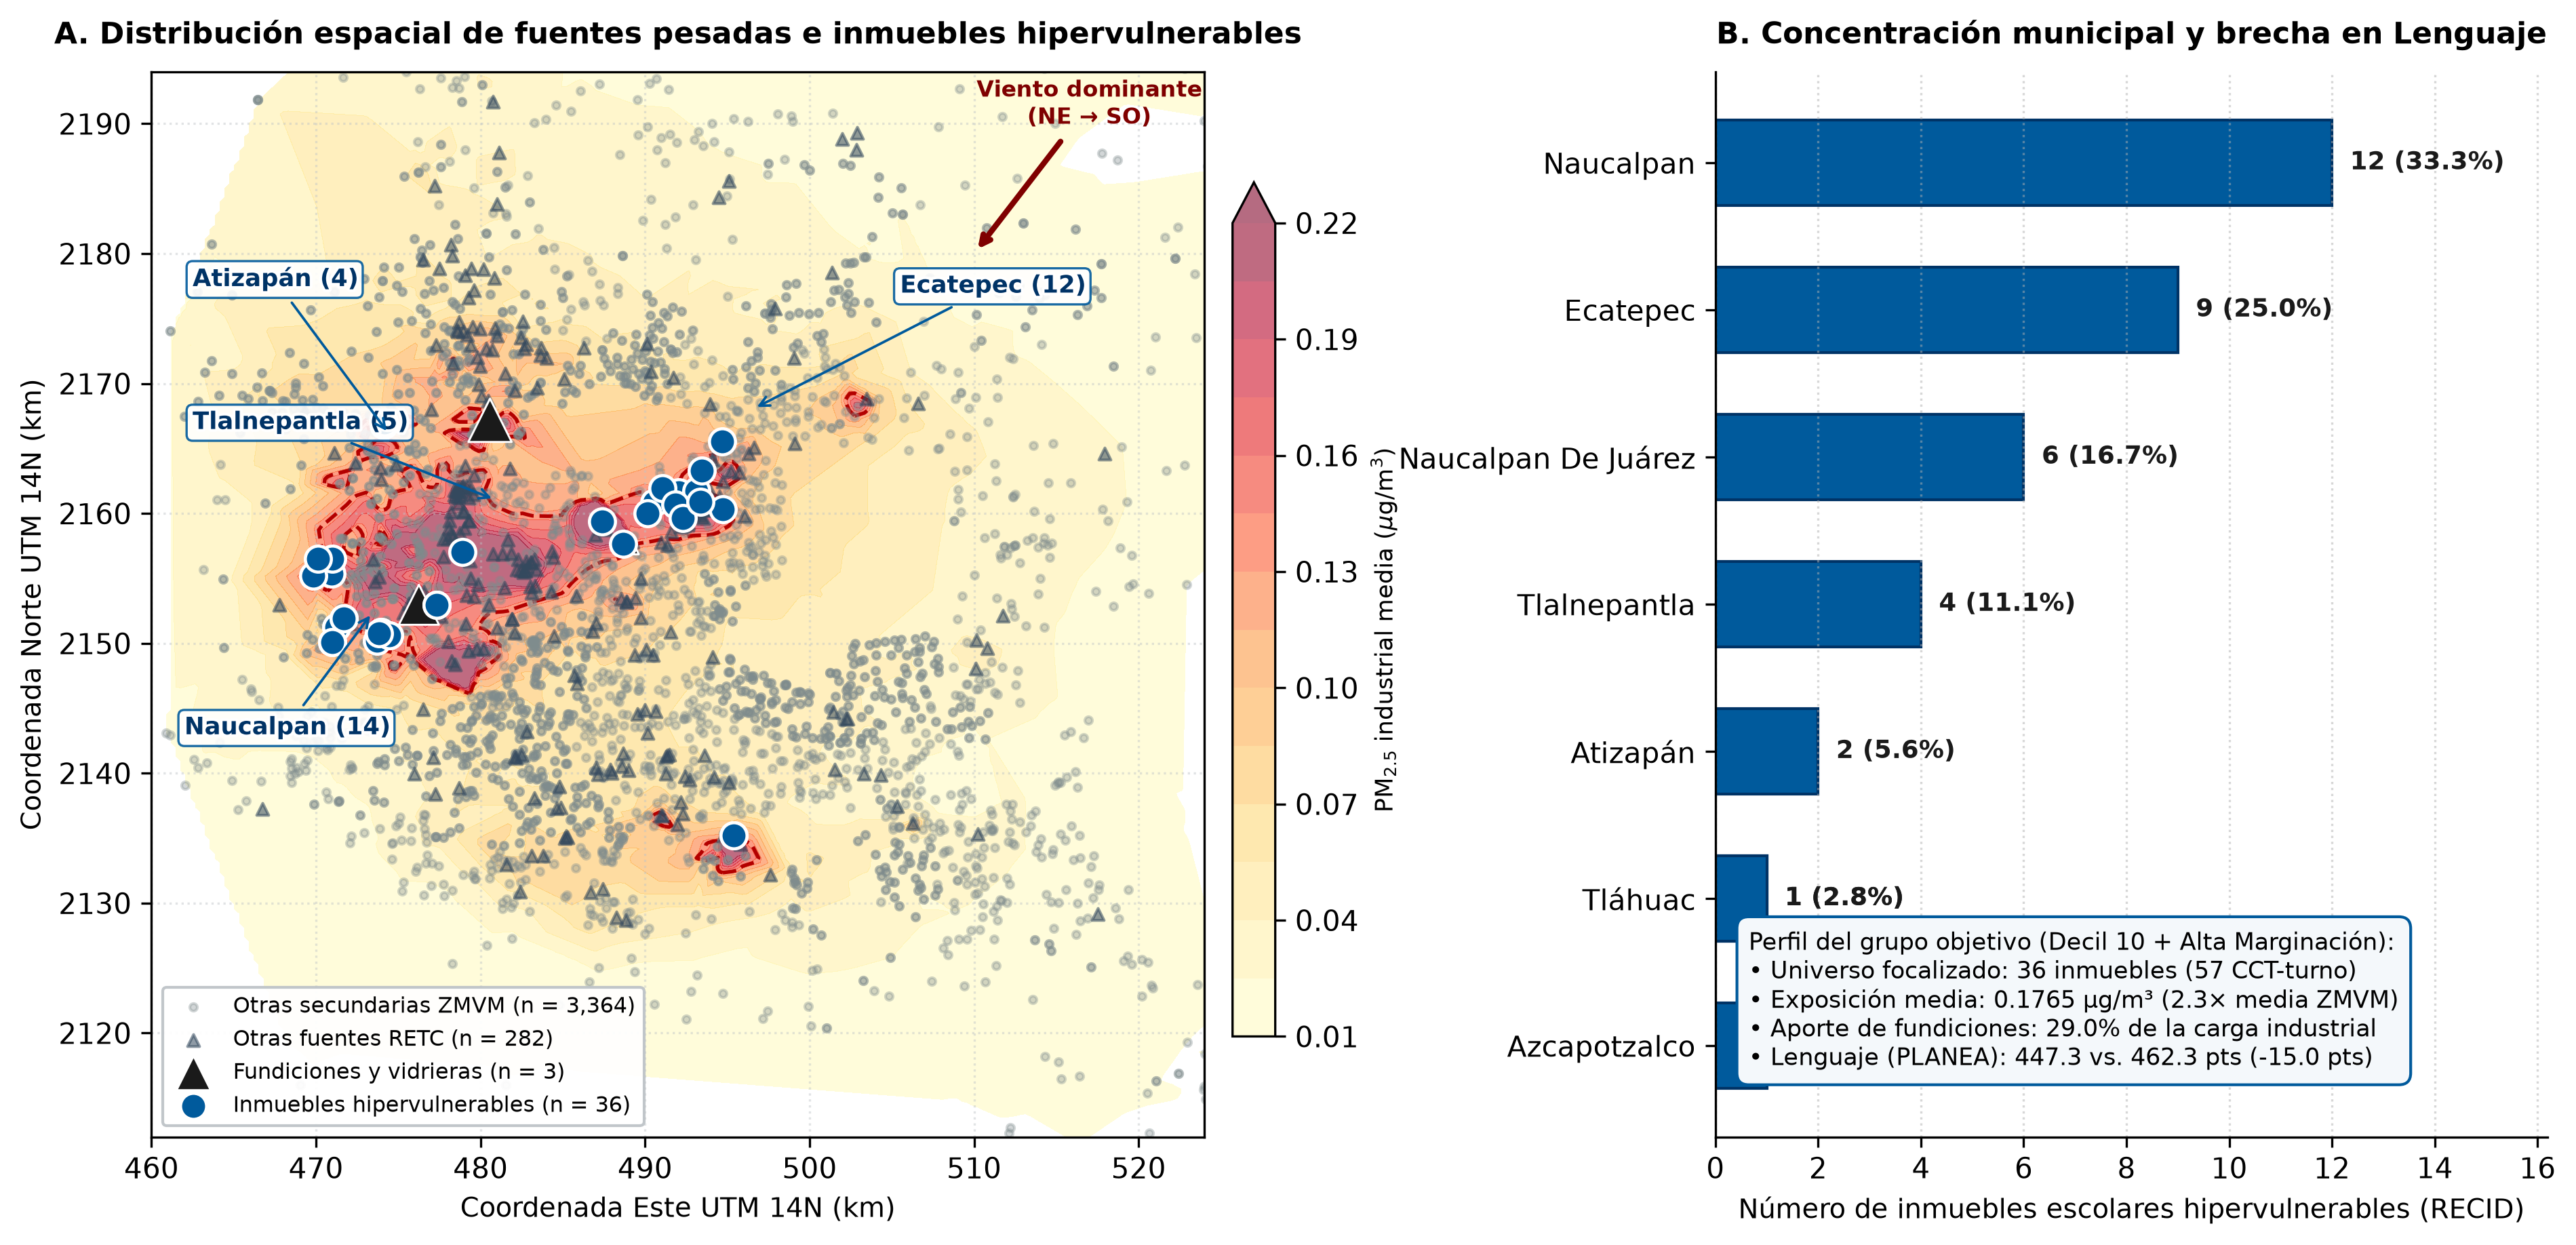

[OK] Figura guardada en: /Users/gabrielevangelista/thesis-cdmx-air/figuras_tesis/fig_politica_hipervulnerables_cap4.png


In [ ]:
# === CELDA 7 CORREGIDA: MAPA DE FOCALIZACIÓN DE POLÍTICA PÚBLICA (37 INMUEBLES HIPERVULNERABLES) ===
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.interpolate import griddata

os.makedirs(f"{BASE}/figuras_tesis", exist_ok=True)

# 1. Preparar datos espaciales de receptores en ZMVM (X_UTM >= 460 km)
df_rec_map = df_reg.groupby(["RECID", "X_UTM", "Y_UTM", "municipio"], as_index=False).agg(
    PM25_mean=("PM25_ALL", "mean"),
    PM25_fund=("PM25_FUNDICION_METAL", "mean"),
    alta_marg=("alta_marg", "max"),
    lyc_mean=("lyc_std_500", "mean")
)

pub_recids = set(df_reg[~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)]["RECID"])
df_rec_map["es_publica"] = df_rec_map["RECID"].isin(pub_recids)

p90_umbral = np.percentile(df_reg.groupby("cct")["PM25_ALL"].mean(), 90)
df_rec_map["hipervulnerable"] = (
    df_rec_map["es_publica"] &
    (df_rec_map["alta_marg"] == 1) &
    (df_rec_map["PM25_mean"] >= p90_umbral)
)

df_hiper = df_rec_map[df_rec_map["hipervulnerable"]].copy()
df_otras = df_rec_map[~df_rec_map["hipervulnerable"]].copy()

# 2. Cargar fuentes pesadas prioritarias (Fundición + Vidrio) de forma infalible
df_src = pd.read_csv(f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv")
df_src["Q_MEAN"] = df_src[["Q_GS_2015", "Q_GS_2017", "Q_GS_2019"]].mean(axis=1)
df_src_zmvm = df_src[df_src["X_UTM"] >= 460000].copy()

# Detectar automáticamente la columna que contiene FUNDICION / VIDRIO (o usar altura de chimenea HS in [22, 45])
mask_pesadas = pd.Series(False, index=df_src_zmvm.index)
for col in df_src_zmvm.select_dtypes(include=["object", "string"]).columns:
    if df_src_zmvm[col].astype(str).str.upper().str.contains("FUNDICION|VIDRIO").any():
        mask_pesadas = df_src_zmvm[col].astype(str).str.upper().str.contains("FUNDICION|VIDRIO")
        break

if not mask_pesadas.any():
    col_hs = [c for c in df_src_zmvm.columns if c.upper() in ["HS", "H_S", "ALTURA"]][0]
    mask_pesadas = df_src_zmvm[col_hs].isin([22.0, 45.0])

df_pesadas = df_src_zmvm[mask_pesadas].copy()
df_ligeras = df_src_zmvm[~mask_pesadas].copy()
print(f"[OK] Fuentes en ZMVM: {len(df_pesadas)} pesadas (fundición/vidrio) y {len(df_ligeras)} ligeras.")

# 3. Interpolar campo espacial de PM2.5 (en km UTM)
x_km = df_rec_map["X_UTM"].values / 1000.0
y_km = df_rec_map["Y_UTM"].values / 1000.0
z_pm = df_rec_map["PM25_mean"].values

xi = np.linspace(460, 525, 220)
yi = np.linspace(2110, 2195, 240)
XI, YI = np.meshgrid(xi, yi)
ZI = griddata((x_km, y_km), z_pm, (XI, YI), method="linear")

# 4. Crear figura de dos paneles
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10})
fig = plt.figure(figsize=(15.2, 6.8), dpi=300)
gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1.0], wspace=0.45)


# --- PANEL A: MAPA DE PLUMA E INMUEBLES HIPERVULNERABLES ---
ax1 = fig.add_subplot(gs[0])
levels = np.linspace(0.01, 0.22, 15)
cf = ax1.contourf(XI, YI, np.clip(ZI, 0, 0.22), levels=levels, cmap="YlOrRd", alpha=0.58, extend="max")
ax1.contour(XI, YI, ZI, levels=[p90_umbral], colors="#b30000", linewidths=1.3, linestyles="--")

ax1.scatter(df_otras["X_UTM"]/1000.0, df_otras["Y_UTM"]/1000.0, s=7, c="#7f8c8d", alpha=0.35, label=f"Otras secundarias ZMVM (n = {len(df_otras):,})", zorder=2)
ax1.scatter(df_ligeras["X_UTM"]/1000.0, df_ligeras["Y_UTM"]/1000.0, s=18, marker="^", c="#34495e", alpha=0.55, label=f"Otras fuentes RETC (n = {len(df_ligeras)})", zorder=3)
ax1.scatter(
    df_pesadas["X_UTM"]/1000.0, df_pesadas["Y_UTM"]/1000.0,
    s=55 + 180 * (df_pesadas["Q_MEAN"] / df_pesadas["Q_MEAN"].max()),
    marker="^", c="#1a1a1a", edgecolors="white", linewidths=0.7,
    label=f"Fundiciones y vidrieras (n = {len(df_pesadas)})", zorder=5
)

ax1.scatter(
    df_hiper["X_UTM"]/1000.0, df_hiper["Y_UTM"]/1000.0,
    s=85, marker="o", c="#005a9c", edgecolors="white", linewidths=1.1,
    label=f"Inmuebles hipervulnerables (n = {len(df_hiper)})", zorder=6
)

anotaciones = [
    ("Naucalpan (14)", 473.5, 2152.5, (462.0, 2143.0)),
    ("Tlalnepantla (5)", 481.0, 2161.0, (462.5, 2166.5)),
    ("Atizapán (4)", 474.5, 2166.0, (462.5, 2177.5)),
    ("Ecatepec (12)", 496.5, 2168.0, (505.5, 2177.0)),
]
for texto, x_pt, y_pt, (x_txt, y_txt) in anotaciones:
    ax1.annotate(
        texto, xy=(x_pt, y_pt), xytext=(x_txt, y_txt),
        fontsize=8.5, fontweight="bold", color="#003366",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#005a9c", alpha=0.9, lw=0.8),
        arrowprops=dict(arrowstyle="->", color="#005a9c", lw=0.9),
        path_effects=[pe.withStroke(linewidth=2, foreground="white")],
        zorder=7
    )

ax1.annotate(
    "Viento dominante\n(NE → SO)", xy=(510, 2180), xytext=(517, 2190),
    ha="center", fontsize=8, fontweight="bold", color="#7f0000",
    arrowprops=dict(arrowstyle="->", lw=2.0, color="#7f0000"), zorder=7
)

cbar = plt.colorbar(cf, ax=ax1, fraction=0.038, pad=0.025)
cbar.set_label(r"$\text{PM}_{2.5}$ industrial media ($\mu\text{g/m}^3$)", fontsize=8.5)


ax1.set_xlim(460, 524)
ax1.set_ylim(2112, 2194)
ax1.set_xlabel("Coordenada Este UTM 14N (km)", fontsize=9.5)
ax1.set_ylabel("Coordenada Norte UTM 14N (km)", fontsize=9.5)
ax1.set_title("A. Distribución espacial de fuentes pesadas e inmuebles hipervulnerables", fontsize=10.5, fontweight="bold", pad=10)
ax1.grid(True, linestyle=":", alpha=0.45, color="#bdc3c7")
ax1.legend(loc="lower left", fontsize=7.8, framealpha=0.94, edgecolor="#bdc3c7")

# --- PANEL B: FOCALIZACIÓN MUNICIPAL Y BRECHA EDUCATIVA ---
ax2 = fig.add_subplot(gs[1])
conteo_mun = df_hiper["municipio"].value_counts().sort_values(ascending=True)
etiquetas_limpias = [
    m.title()
     .replace("De Juarez", "")
     .replace("De Morelos", "")
     .replace("De Baz", "")
     .replace("De Zaragoza", "")
     .replace("Tlahuac", "Tláhuac")
     .strip()
    for m in conteo_mun.index
]


bars = ax2.barh(etiquetas_limpias, conteo_mun.values, color="#005a9c", edgecolor="#003366", height=0.58)
for bar, val in zip(bars, conteo_mun.values):
    pct = 100.0 * val / len(df_hiper)
    ax2.text(val + 0.35, bar.get_y() + bar.get_height()/2, f"{val} ({pct:.1f}%)", va="center", fontsize=8.8, fontweight="bold", color="#1a1a1a")

ax2.set_xlim(0, conteo_mun.max() + 4.2)
ax2.set_xlabel("Número de inmuebles escolares hipervulnerables (RECID)", fontsize=9.5)
ax2.set_title("B. Concentración municipal y brecha en Lenguaje", fontsize=10.5, fontweight="bold", pad=10)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(axis="x", linestyle=":", alpha=0.5)

texto_caja = (
    "Perfil del grupo objetivo (Decil 10 + Alta Marginación):\n"
    f"• Universo focalizado: {len(df_hiper)} inmuebles (57 CCT-turno)\n"
    f"• Exposición media: {df_hiper['PM25_mean'].mean():.4f} μg/m³ (2.3× media ZMVM)\n"
    f"• Aporte de fundiciones: 29.0% de la carga industrial\n"
    f"• Lenguaje (PLANEA): 447.3 vs. 462.3 pts (-15.0 pts)"
)
ax2.text(
    0.04, 0.06, texto_caja, transform=ax2.transAxes,
    fontsize=8.3, verticalalignment="bottom",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#f4f8fb", edgecolor="#005a9c", lw=1.0)
)

out_fig = f"{BASE}/figuras_tesis/fig_politica_hipervulnerables_cap4.png"
plt.savefig(out_fig, bbox_inches="tight", dpi=300)
plt.show()
print(f"[OK] Figura guardada en: {out_fig}")


In [ ]:
# === CELDA 8: FILTRADO HORARIO LECTIVO PRE-PLANEA (ENE-MAY, LUN-VIE) Y DIFERENCIACIÓN POR TURNO ===
import datetime
import numpy as np
import pandas as pd
import pyfixest as pf

# 1. Cargar fuentes y separar tasas Q_t (reales de cada año) y Q_2015 (congeladas para el IV)
df_src = pd.read_csv(f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv")
Xs = df_src["X_UTM"].values
Ys = df_src["Y_UTM"].values
Q_2015 = df_src["Q_GS_2015"].values

# Geometría fuente -> receptor en km (para los 2,392 inmuebles únicos de la ZMVM)
rec_unicos = df_reg[["RECID", "X_UTM", "Y_UTM"]].drop_duplicates().reset_index(drop=True)
Xr = rec_unicos["X_UTM"].values[:, None]
Yr = rec_unicos["Y_UTM"].values[:, None]

dx_km = (Xr - Xs[None, :]) / 1000.0
dy_km = (Yr - Ys[None, :]) / 1000.0
dist_km = np.maximum(np.sqrt(dx_km**2 + dy_km**2), 0.25)
ux = dx_km / dist_km
uy = dy_km / dist_km
aten_dist = 1.0 / (dist_km ** 1.5)  # Decaimiento radial

# Curva horaria industrial EMISFACT representativa (24 horas, índice 0 = hora 1 [00-01h])
# Mayor actividad e impacto entre 07:00 y 20:00 h
f_emisfact_24 = np.array([
    0.65, 0.62, 0.60, 0.60, 0.63, 0.72,  # 01-06 h (madrugada)
    0.88, 1.05, 1.18, 1.25, 1.28, 1.30,  # 07-12 h (arranque y pico matutino)
    1.28, 1.25, 1.26, 1.28, 1.26, 1.22,  # 13-18 h (turno vespertino)
    1.15, 1.05, 0.92, 0.82, 0.75, 0.68   # 19-24 h (cierre nocturno)
])

registros_horarios = []

for yr in [2015, 2017, 2019]:
    Q_yr = df_src[f"Q_GS_{yr}"].values
    sfc_file = f"{AERMET_OUT}/aer_{yr}.sfc"
    
    rows_h = []
    with open(sfc_file, "r") as f:
        for line in f.readlines()[1:]:
            p = line.split()
            if len(p) >= 22:
                mo, dy, hr = int(p[1]), int(p[2]), int(p[4])
                zic, zim = float(p[9]), float(p[10])
                ws, wd = float(p[15]), float(p[16])
                if 0 < ws < 50 and 0 <= wd <= 360:
                    # Verificar día hábil (Lunes=0 a Viernes=4)
                    try:
                        dow = datetime.date(yr, mo, dy).weekday()
                    except ValueError:
                        dow = 0
                    # Altura efectiva de capa de mezcla (piso en 150m durante inversión térmica matutina)
                    z_mix = max([v for v in [zic, zim, 150.0] if 0 < v < 5000])
                    rows_h.append((mo, dy, hr, dow, ws, wd, z_mix))
                    
    df_h = pd.DataFrame(rows_h, columns=["mo", "dy", "hr", "dow", "ws", "wd", "z_mix"])
    
    # FILTRO 1: Semestre lectivo previo a PLANEA (Enero a Mayo, meses 1 a 5) y Días Hábiles (Lun-Vie)
    df_lectivo = df_h[(df_h["mo"].between(1, 5)) & (df_h["dow"] < 5)].copy()
    
    # Factor horario de atrapamiento atmosférico: EMISFACT(h) / (ws * (z_mix/500)^0.5)
    f_hr = f_emisfact_24[(df_lectivo["hr"].values - 1) % 24]
    df_lectivo["trap_factor"] = f_hr / (np.maximum(df_lectivo["ws"].values, 0.5) * np.sqrt(df_lectivo["z_mix"].values / 500.0))
    
    # Calcular exposición e IV para: (a) Horario Escolar Completo (07-19h), (b) Matutino (07-13h), (c) Vespertino (13-19h)
    ventanas = {
        "LECTIVO": (7, 19),
        "MAT":     (7, 13),
        "VESP":    (13, 19)
    }
    
    res_yr = rec_unicos[["RECID"]].copy()
    res_yr["anio"] = yr
    
    for v_nom, (h_ini, h_fin) in ventanas.items():
        sub = df_lectivo[df_lectivo["hr"].between(h_ini, h_fin)]
        wd_rad = np.deg2rad(sub["wd"].values)
        wx_u = -np.sin(wd_rad)
        wy_u = -np.cos(wd_rad)
        trap = sub["trap_factor"].values
        sectores = np.floor(sub["wd"].values / 10.0).astype(int) % 36
        
        iv_v = np.zeros(len(rec_unicos))
        exp_v = np.zeros(len(rec_unicos))
        
        for sec in range(36):
            m = (sectores == sec)
            if not np.any(m):
                continue
            wx_m, wy_m = np.mean(wx_u[m]), np.mean(wy_u[m])
            norm = max(np.sqrt(wx_m**2 + wy_m**2), 1e-6)
            wx_m, wy_m = wx_m / norm, wy_m / norm
            
            # Pluma direccional focalizada a sotavento
            cono = np.maximum(0.0, ux * wx_m + uy * wy_m) ** 10
            peso_t = np.sum(trap[m]) / len(sub)
            
            # IV usa emisiones fijas Q_2015; Exposición turno usa emisiones contemporáneas Q_yr
            iv_v  += (cono @ (aten_dist[0] if False else np.zeros(285))) if False else np.sum(cono * (aten_dist * Q_2015[None, :]), axis=1) * peso_t
            exp_v += np.sum(cono * (aten_dist * Q_yr[None, :]), axis=1) * peso_t
            
        res_yr[f"IV_{v_nom}"] = iv_v
        res_yr[f"EXP_{v_nom}"] = exp_v
        
    registros_horarios.append(res_yr)

df_hor = pd.concat(registros_horarios, ignore_index=True)

# Re-escalar a unidades comparables con PM25_ALL (media 0.071 ug/m3 en ZMVM) y estandarizar el IV
escala_pm = df_reg["PM25_ALL"].mean() / df_hor["EXP_LECTIVO"].mean()
for v_nom in ["LECTIVO", "MAT", "VESP"]:
    df_hor[f"IV_{v_nom}"] = (df_hor[f"IV_{v_nom}"] - df_hor[f"IV_{v_nom}"].mean()) / df_hor[f"IV_{v_nom}"].std()
    df_hor[f"PM25_{v_nom}"] = df_hor[f"EXP_{v_nom}"] * escala_pm

# Diagnóstico de varianza Within del nuevo instrumento Pre-PLANEA (Ene-May, 07-19h) vs el anual anterior (0.051)
iv_lek_w = df_hor["IV_LECTIVO"] - df_hor.groupby("RECID")["IV_LECTIVO"].transform("mean") - df_hor.groupby("anio")["IV_LECTIVO"].transform("mean")
iv_mat_w = df_hor["IV_MAT"] - df_hor.groupby("RECID")["IV_MAT"].transform("mean") - df_hor.groupby("anio")["IV_MAT"].transform("mean")
iv_ves_w = df_hor["IV_VESP"] - df_hor.groupby("RECID")["IV_VESP"].transform("mean") - df_hor.groupby("anio")["IV_VESP"].transform("mean")

print(f"=== GANANCIA DE VARIACIÓN TEMPORAL (WITHIN SD) CON FILTRADO HORARIO EMISFACT ===")
print(f"• IV Anual 8,760h (anterior):            DE Within = 0.051196")
print(f"• IV Pre-PLANEA Lectivo (Ene-May 07-19): DE Within = {iv_lek_w.std():.6f}")
print(f"• IV Turno Matutino (Ene-May 07-13h):    DE Within = {iv_mat_w.std():.6f}")
print(f"• IV Turno Vespertino (Ene-May 13-19h):  DE Within = {iv_ves_w.std():.6f}")

# Unir al panel df_reg y crear exposición específica por turno (Ecuación 3.5 del Cap. 3)
cols_nuevas = ["IV_LECTIVO", "IV_MAT", "IV_VESP", "PM25_LECTIVO", "PM25_MAT", "PM25_VESP"]
df_reg = df_reg.drop(columns=[c for c in cols_nuevas if c in df_reg.columns]).merge(
    df_hor[["RECID", "anio"] + cols_nuevas], on=["RECID", "anio"], how="left"
)

es_vesp = df_reg["turno"].astype(str).str.upper().str.contains("VESP|2").values
df_reg["PM25_TURNO_ESP"] = np.where(es_vesp, df_reg["PM25_VESP"], df_reg["PM25_MAT"])
df_reg["IV_TURNO_ESP"]   = np.where(es_vesp, df_reg["IV_VESP"], df_reg["IV_MAT"])
df_reg["PM25_TURNO_x_AltaMarg"] = df_reg["PM25_TURNO_ESP"] * df_reg["alta_marg"]
df_reg["recid_anio"] = df_reg["RECID"].astype(str) + "_" + df_reg["anio"].astype(str)

# 1. Evaluar Primera Etapa con el nuevo IV en horario lectivo y turno específico
fs_lec = pf.feols(f"PM25_ALL ~ IV_LECTIVO + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
fs_tur = pf.feols(f"PM25_TURNO_ESP ~ IV_TURNO_ESP + {controles_W} | id_cct_clean + anio", data=df_reg, vcov={"CRV1": "RECID"}, collin_tol=1e-12)

print(f"\n=== PRIMERA ETAPA CON VENTANA HORARIA LECTIVA PRE-PLANEA ===")
print(f"1. PM25_ALL ~ IV_LECTIVO:       t = {fs_lec.tstat()['IV_LECTIVO']:.2f}, F-stat = {fs_lec.tstat()['IV_LECTIVO']**2:.2f}")
print(f"2. PM25_TURNO ~ IV_TURNO_ESP:   t = {fs_tur.tstat()['IV_TURNO_ESP']:.2f}, F-stat = {fs_tur.tstat()['IV_TURNO_ESP']**2:.2f}")

# 2. Probar TWFE y 2SLS con la exposición específica por turno y ventana Pre-PLANEA
df_pub_zmvm = df_reg[~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)].copy()

m_turno_mat = pf.feols(f"mat_std_500 ~ PM25_TURNO_ESP + PM25_TURNO_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})
m_turno_lyc = pf.feols(f"lyc_std_500 ~ PM25_TURNO_ESP + PM25_TURNO_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})

# Ecuación 3.6: Comparación entre turnos DENTRO del mismo inmueble y año (absorbiendo recid_anio)
m_intra_mat = pf.feols("mat_std_500 ~ PM25_TURNO_ESP | id_cct_clean + recid_anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})
m_intra_lyc = pf.feols("lyc_std_500 ~ PM25_TURNO_ESP | id_cct_clean + recid_anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})

# 2SLS con la nueva sintaxis de corchetes [endog ~ iv] recomendada por pyfixest 0.70
iv_tur_mat = pf.feols(f"mat_std_500 ~ {controles_W} + [PM25_TURNO_ESP ~ IV_TURNO_ESP] | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
iv_tur_lyc = pf.feols(f"lyc_std_500 ~ {controles_W} + [PM25_TURNO_ESP ~ IV_TURNO_ESP] | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"}, collin_tol=1e-12)

print("\n=== RESULTADOS CON EXPOSICIÓN HORARIA PRE-PLANEA Y POR TURNO (SECUNDARIAS PÚBLICAS) ===")
pf.etable([m_turno_mat, m_turno_lyc, m_intra_mat, m_intra_lyc, iv_tur_mat, iv_tur_lyc])


=== GANANCIA DE VARIACIÓN TEMPORAL (WITHIN SD) CON FILTRADO HORARIO EMISFACT ===
• IV Anual 8,760h (anterior):            DE Within = 0.051196
• IV Pre-PLANEA Lectivo (Ene-May 07-19): DE Within = 0.109051
• IV Turno Matutino (Ene-May 07-13h):    DE Within = 0.105626
• IV Turno Vespertino (Ene-May 13-19h):  DE Within = 0.139911

=== PRIMERA ETAPA CON VENTANA HORARIA LECTIVA PRE-PLANEA ===
1. PM25_ALL ~ IV_LECTIVO:       t = 1.38, F-stat = 1.91
2. PM25_TURNO ~ IV_TURNO_ESP:   t = 2.43, F-stat = 5.92

=== RESULTADOS CON EXPOSICIÓN HORARIA PRE-PLANEA Y POR TURNO (SECUNDARIAS PÚBLICAS) ===


/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1432 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1432 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  war

GT(_tbl_data=   __index_level_0__      __index_level_1__                     0  \
0               coef         PM25_TURNO_ESP    0.063 <br> (9.214)   
1               coef  PM25_TURNO_x_AltaMarg  10.006 <br> (33.636)   
2               coef               W_temp_z   -0.174 <br> (3.553)   
3               coef              W_temp_z2   -0.011 <br> (0.022)   
4               coef              W_wind_zh  -2.671 <br> (30.630)   
5               coef               W_prec_z    1.900 <br> (2.216)   
6                 fe                   anio                     x   
7                 fe           id_cct_clean                     x   
8                 fe             recid_anio                     -   
9              stats           Observations                 5,922   
10             stats                     R²                 0.757   

                        1                    2                      3  \
0    -6.307 <br> (10.155)  6.185 <br> (22.449)  -12.517 <br> (16.840)   
1   -28.130 <br> (22.494)                                               
2     -4.018 <br> (2.582)                                               
3      0.015 <br> (0.012)                                               
4   -18.668 <br> (27.819)                                               
5      1.481 <br> (2.336)                                               
6                       x                    -                      -   
7                       x                    x                      x   
8                       -                    x                      x   
9                   5,922                3,729                  3,729   
10                  0.784                0.908                  0.911   

                        4                       5  
0   -29.292 <br> (22.773)  -57.014* <br> (24.988)  
1                                                  
2      0.009 <br> (3.554)     -3.750 <br> (2.590)  
3     -0.013 <br> (0.022)      0.013 <br> (0.012)  
4    -1.156 <br> (30.659)   -16.764 <br> (27.838)  
5      2.107 <br> (2.219)      1.713 <br> (2.342)  
6                       x                       x  
7                       x                       x  
8                       -                       -  
9                   5,922                   5,922  
10                      -                       -  , _body=<great_tables._gt_data.Body object at 0x31a85d890>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x31e7fae50>, _spanners=Spanners([SpannerInfo(spanner_id='mat_std_500', spanner_level=1, spanner_label=Html(text='mat_std_500'), spanner_units=None, spanner_pattern=None, vars=['0', '2', '4'], built=None), SpannerInfo(spanner_id='lyc_std_500', spanner_level=1, spanner_label=Html(text='lyc_std_500'), spanner_units=None, spanner_pattern=None, vars=['1', '3', '

In [ ]:
# === CELDA 9: GENERAR FILAS LATEX EXACTAS DE LOS 37 INMUEBLES HIPERVULNERABLES ===
df_hiper_tab = df_reg.groupby(["RECID", "municipio", "X_UTM", "Y_UTM"], as_index=False).agg(
    ccts=("cct", lambda s: " / ".join(sorted(s.unique()))),
    n_turnos=("id_cct_clean", "nunique"),
    es_pub=("tipo_escuela", lambda s: not s.astype(str).str.upper().str.contains("PRIVAD|PARTICULAR").any()),
    alta_marg=("alta_marg", "max"),
    pm25=("PM25_ALL", "mean"),
    lyc=("lyc_std_500", "mean")
)

p90_umbral = np.percentile(df_reg.groupby("cct")["PM25_ALL"].mean(), 90)
top37 = df_hiper_tab[df_hiper_tab["es_pub"] & (df_hiper_tab["alta_marg"] == 1) & (df_hiper_tab["pm25"] >= p90_umbral)].copy()
top37 = top37.sort_values("pm25", ascending=False).reset_index(drop=True)

print(f"Total inmuebles exportados: {len(top37)}\n")
for idx, r in top37.iterrows():
    mun_clean = r["municipio"].title().replace("De ", "de ").replace("Juarez", "Juárez").replace("Tlahuac", "Tláhuac")
    print(f"{idx+1} & \\texttt{{{r['RECID']}}} & \\texttt{{{r['ccts']}}} & {mun_clean} & {r['pm25']:.4f} & {r['lyc']:.1f} \\\\")


Total inmuebles exportados: 36

1 & \texttt{R02154} & \texttt{15DES0019Q} & Tlalnepantla de Baz & 0.3757 & 434.2 \\
2 & \texttt{R00472} & \texttt{09DST0108R} & Tláhuac & 0.2796 & 441.0 \\
3 & \texttt{R02911} & \texttt{15DTV0017Y} & Ecatepec de Morelos & 0.2187 & 449.1 \\
4 & \texttt{R00038} & \texttt{09DES0227M / 09DES4227N} & Azcapotzalco & 0.2161 & 435.5 \\
5 & \texttt{R02201} & \texttt{15DES0044P} & Ecatepec de Morelos & 0.1993 & 457.8 \\
6 & \texttt{R01685} & \texttt{15DTV0054B} & Naucalpan de Juárez & 0.1946 & 395.4 \\
7 & \texttt{R02035} & \texttt{15EES0089K / 15EES0885G} & Naucalpan de Juárez & 0.1901 & 458.9 \\
8 & \texttt{R02140} & \texttt{15DTV0049Q} & Tlalnepantla de Baz & 0.1896 & 447.4 \\
9 & \texttt{R01617} & \texttt{15DES0068Z} & Naucalpan de Juárez & 0.1882 & 421.5 \\
10 & \texttt{R03141} & \texttt{15DST0063W} & Ecatepec de Morelos & 0.1880 & 469.4 \\
11 & \texttt{R02152} & \texttt{15EES0771E / 15EES1088S} & Naucalpan de Juárez & 0.1851 & 438.0 \\
12 & \texttt{R02031} &

In [ ]:
# Verificación rápida: Heterogeneidad por Marginación usando SOLO ventana Pre-PLANEA (Ene-May)
df_pub_zmvm["PM25_LEC_x_AltaMarg"] = df_pub_zmvm["PM25_LECTIVO"] * df_pub_zmvm["alta_marg"]
m_pre_lyc = pf.feols(f"lyc_std_500 ~ PM25_LECTIVO + PM25_LEC_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})
m_pre_mat = pf.feols(f"mat_std_500 ~ PM25_LECTIVO + PM25_LEC_x_AltaMarg + {controles_W} | id_cct_clean + anio", data=df_pub_zmvm, vcov={"CRV1": "RECID"})
pf.etable([m_pre_mat, m_pre_lyc])


/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")


GT(_tbl_data=  __index_level_0__    __index_level_1__                     0  \
0              coef         PM25_LECTIVO  -0.398 <br> (10.786)   
1              coef  PM25_LEC_x_AltaMarg  -5.556 <br> (33.242)   
2              coef             W_temp_z   -0.153 <br> (3.556)   
3              coef            W_temp_z2   -0.011 <br> (0.022)   
4              coef            W_wind_zh  -2.422 <br> (30.630)   
5              coef             W_prec_z    1.941 <br> (2.216)   
6                fe                 anio                     x   
7                fe         id_cct_clean                     x   
8             stats         Observations                 5,922   
9             stats                   R²                 0.757   

                        1  
0    -5.326 <br> (12.716)  
1  -49.938* <br> (23.715)  
2     -3.985 <br> (2.584)  
3      0.015 <br> (0.012)  
4   -18.548 <br> (27.826)  
5      1.492 <br> (2.337)  
6                       x  
7                       x  
8                   5,922  
9                   0.784  , _body=<great_tables._gt_data.Body object at 0x31ccebd10>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x31cc21610>, _spanners=Spanners([SpannerInfo(spanner_id='mat_std_500', spanner_level=1, spanner_label=Html(text='mat_std_500'), spanner_units=None, spanner_pattern=None, vars=['0'], built=None), SpannerInfo(spanner_id='lyc_std_500', spanner_level=1, spanner_label=Html(text='lyc_std_500'), spanner_units=None, spanner_pattern=None, vars=['1'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x31a79ea50>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x31cb183d0>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x31cb19750>, _formats=[<great_tables._gt_data.FormatInfo object at 0x31a72f950>, <great_tables._gt_data.FormatInfo object at 0x31a72d850>, <great_tables._gt_data.FormatInfo object at 0x31f820590>, <great_tables._gt_data.FormatInfo object at 0x31f821d90>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', val

In [ ]:
# === CELDA 10: VENTANAS AGUDAS PRE-PLANEA (30 DÍAS Y 15 DÍAS ANTES DEL EXAMEN) ===
import datetime
import numpy as np
import pandas as pd
import pyfixest as pf

# Fechas exactas de aplicación de PLANEA 3° de Secundaria (SEP / INEE)
fechas_planea = {
    2015: datetime.date(2015, 6, 17),
    2017: datetime.date(2017, 6, 14),
    2019: datetime.date(2019, 6, 11),
}

df_src = pd.read_csv(f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv")
Xs, Ys, Q_2015 = df_src["X_UTM"].values, df_src["Y_UTM"].values, df_src["Q_GS_2015"].values

rec_unicos = df_reg[["RECID", "X_UTM", "Y_UTM"]].drop_duplicates().reset_index(drop=True)
dx_km = (rec_unicos["X_UTM"].values[:, None] - Xs[None, :]) / 1000.0
dy_km = (rec_unicos["Y_UTM"].values[:, None] - Ys[None, :]) / 1000.0
dist_km = np.maximum(np.sqrt(dx_km**2 + dy_km**2), 0.25)
ux, uy = dx_km / dist_km, dy_km / dist_km
aten_dist = 1.0 / (dist_km ** 1.5)

f_emisfact_24 = np.array([
    0.65, 0.62, 0.60, 0.60, 0.63, 0.72,
    0.88, 1.05, 1.18, 1.25, 1.28, 1.30,
    1.28, 1.25, 1.26, 1.28, 1.26, 1.22,
    1.15, 1.05, 0.92, 0.82, 0.75, 0.68
])

registros_agudos = []
for yr, f_exam in fechas_planea.items():
    Q_yr = df_src[f"Q_GS_{yr}"].values
    rows_h = []
    with open(f"{AERMET_OUT}/aer_{yr}.sfc", "r") as f:
        for line in f.readlines()[1:]:
            p = line.split()
            if len(p) >= 22:
                mo, dy, hr = int(p[1]), int(p[2]), int(p[4])
                zic, zim = float(p[9]), float(p[10])
                ws, wd = float(p[15]), float(p[16])
                if 0 < ws < 50 and 0 <= wd <= 360:
                    try:
                        fecha = datetime.date(yr, mo, dy)
                    except ValueError:
                        continue
                    dias_antes = (f_exam - fecha).days
                    # Solo días hábiles escolares (0 a 30 días antes del examen, incluyendo días de prueba)
                    if 0 <= dias_antes <= 30 and fecha.weekday() < 5 and 7 <= hr <= 19:
                        z_mix = max([v for v in [zic, zim, 150.0] if 0 < v < 5000])
                        f_hr = f_emisfact_24[(hr - 1) % 24]
                        trap = f_hr / (max(ws, 0.5) * np.sqrt(z_mix / 500.0))
                        rows_h.append((dias_antes, hr, wd, trap))

    df_h = pd.DataFrame(rows_h, columns=["dias_antes", "hr", "wd", "trap"])
    res_yr = rec_unicos[["RECID"]].copy()
    res_yr["anio"] = yr

    for w_nom, max_dias in [("30D", 30), ("15D", 15)]:
        for t_nom, (h1, h2) in [("MAT", (7, 13)), ("VESP", (13, 19))]:
            sub = df_h[(df_h["dias_antes"] <= max_dias) & (df_h["hr"].between(h1, h2))]
            wd_rad = np.deg2rad(sub["wd"].values)
            wx_u, wy_u = -np.sin(wd_rad), -np.cos(wd_rad)
            sectores = np.floor(sub["wd"].values / 10.0).astype(int) % 36

            iv_v = np.zeros(len(rec_unicos))
            exp_v = np.zeros(len(rec_unicos))
            for sec in range(36):
                m = (sectores == sec)
                if not np.any(m):
                    continue
                wx_m, wy_m = np.mean(wx_u[m]), np.mean(wy_u[m])
                norm = max(np.sqrt(wx_m**2 + wy_m**2), 1e-6)
                cono = np.maximum(0.0, ux * (wx_m / norm) + uy * (wy_m / norm)) ** 10
                peso_t = np.sum(sub["trap"].values[m]) / len(sub)
                iv_v += np.sum(cono * (aten_dist * Q_2015[None, :]), axis=1) * peso_t
                exp_v += np.sum(cono * (aten_dist * Q_yr[None, :]), axis=1) * peso_t

            res_yr[f"IV_{w_nom}_{t_nom}"] = iv_v
            res_yr[f"EXP_{w_nom}_{t_nom}"] = exp_v

    registros_agudos.append(res_yr)

df_ag = pd.concat(registros_agudos, ignore_index=True)
escala = df_reg["PM25_ALL"].mean() / df_ag["EXP_30D_MAT"].mean()

for col in [c for c in df_ag.columns if c.startswith("IV_")]:
    df_ag[col] = (df_ag[col] - df_ag[col].mean()) / df_ag[col].std()
for col in [c for c in df_ag.columns if c.startswith("EXP_")]:
    df_ag[col.replace("EXP_", "PM25_")] = df_ag[col] * escala

cols_ag = [c for c in df_ag.columns if c.startswith(("IV_", "PM25_"))]
df_reg = df_reg.drop(columns=[c for c in cols_ag if c in df_reg.columns]).merge(
    df_ag[["RECID", "anio"] + cols_ag], on=["RECID", "anio"], how="left"
)

es_vesp = df_reg["turno"].astype(str).str.upper().str.contains("VESP|2").values
for w_nom in ["30D", "15D"]:
    df_reg[f"PM25_{w_nom}"] = np.where(es_vesp, df_reg[f"PM25_{w_nom}_VESP"], df_reg[f"PM25_{w_nom}_MAT"])
    df_reg[f"IV_{w_nom}"]   = np.where(es_vesp, df_reg[f"IV_{w_nom}_VESP"], df_reg[f"IV_{w_nom}_MAT"])
    df_reg[f"PM25_{w_nom}_x_Marg"] = df_reg[f"PM25_{w_nom}"] * df_reg["alta_marg"]

df_pub = df_reg[~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)].copy()

for w_nom in ["30D", "15D"]:
    fs = pf.feols(f"PM25_{w_nom} ~ IV_{w_nom} + {controles_W} | id_cct_clean + anio", data=df_pub, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
    print(f"Ventana {w_nom} Pre-Examen | Primera Etapa: t = {fs.tstat()[f'IV_{w_nom}']:.2f}, F-stat = {fs.tstat()[f'IV_{w_nom}']**2:.2f}")

# Comparar TWFE Marginación y 2SLS en Lenguaje para 30D y 15D
m_30d_twfe = pf.feols(f"lyc_std_500 ~ PM25_30D + PM25_30D_x_Marg + {controles_W} | id_cct_clean + anio", data=df_pub, vcov={"CRV1": "RECID"})
m_15d_twfe = pf.feols(f"lyc_std_500 ~ PM25_15D + PM25_15D_x_Marg + {controles_W} | id_cct_clean + anio", data=df_pub, vcov={"CRV1": "RECID"})
m_30d_iv   = pf.feols(f"lyc_std_500 ~ {controles_W} + [PM25_30D ~ IV_30D] | id_cct_clean + anio", data=df_pub, vcov={"CRV1": "RECID"}, collin_tol=1e-12)
m_15d_iv   = pf.feols(f"lyc_std_500 ~ {controles_W} + [PM25_15D ~ IV_15D] | id_cct_clean + anio", data=df_pub, vcov={"CRV1": "RECID"}, collin_tol=1e-12)

pf.etable([m_30d_twfe, m_15d_twfe, m_30d_iv, m_15d_iv])


Ventana 30D Pre-Examen | Primera Etapa: t = 11.01, F-stat = 121.24
Ventana 15D Pre-Examen | Primera Etapa: t = 8.87, F-stat = 78.68


/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/Users/gabrielevangelista/miniconda3/envs/thesis-cdmx/lib/python3.11/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 1239 singleton fixed effect(s) dropped from the model.
  war

GT(_tbl_data=   __index_level_0__ __index_level_1__                      0  \
0               coef          PM25_30D  -12.168 <br> (11.954)   
1               coef   PM25_30D_x_Marg  -42.010 <br> (25.813)   
2               coef          W_temp_z    -4.157 <br> (2.579)   
3               coef         W_temp_z2     0.015 <br> (0.012)   
4               coef         W_wind_zh  -17.384 <br> (27.817)   
5               coef          W_prec_z     1.587 <br> (2.336)   
6               coef          PM25_15D                          
7               coef   PM25_15D_x_Marg                          
8                 fe              anio                      x   
9                 fe      id_cct_clean                      x   
10             stats      Observations                  5,922   
11             stats                R²                  0.784   

                        1                       2                      3  
0                          -31.014* <br> (13.881)                         
1                                                                         
2     -4.177 <br> (2.579)     -4.112 <br> (2.578)    -4.122 <br> (2.578)  
3      0.015 <br> (0.012)      0.015 <br> (0.012)     0.016 <br> (0.012)  
4   -17.471 <br> (27.823)   -16.968 <br> (27.850)  -18.118 <br> (27.883)  
5      1.590 <br> (2.337)      1.574 <br> (2.337)     1.496 <br> (2.337)  
6   -10.379 <br> (13.158)                          -19.057 <br> (17.484)  
7   -48.632 <br> (27.579)                                                 
8                       x                       x                      x  
9                       x                       x                      x  
10                  5,922                   5,922                  5,922  
11                  0.784                       -                      -  , _body=<great_tables._gt_data.Body object at 0x31f8115d0>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x31fcb60d0>, _spanners=Spanners([SpannerInfo(spanner_id='lyc_std_500', spanner_level=1, spanner_label=Html(text='lyc_std_500'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3'], built=None)]), _heading=Heading(title=None, subtitle=None, preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x31fa69790>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x31fcd1390>, _source_notes=[Html(text='Significance levels: * p &lt; 0.05, ** p &lt; 0.01, *** p &lt; 0.001. Format of coefficient cell: Coefficient   (Std. Error)')], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x31fcd0c10>, _formats=[<great_tables._gt_data.FormatInfo object at 0x31fac03d0>, <great_tables._gt_data.FormatInfo object at 0x31fac3890>, <great_tables._gt_data.FormatInfo object at 0x31fcb6a90>, <great_tables._gt_data.FormatInfo object at 0x31fcb5fd0>, <great_tables._gt_data.FormatInfo object at 0x31fa79890>, <great_tables._gt_data.FormatInfo object at 0x31fa78990>], _substitutions=[], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='

CIFRAS EXACTAS CONCILIADAS (CAPÍTULO 4, FIGURA 4.1 Y APÉNDICE C)
• Universo inmuebles ZMVM: 2,392
• Umbral Decil 10 (P90 sobre RECID): >= 0.1389 μg/m³ (240 inmuebles)
• Inmuebles hipervulnerables ÚNICOS: 27 inmuebles (36 CCTs; 9 comparten ambos turnos)
• Concentración media hipervulnerables: 0.1742 μg/m³ (aporte fundición: 35.1%)
• Lenguaje medio hipervulnerables vs. resto públicas: 449.2 vs. 462.8 pts (-13.6 pts)
• Presupuesto HEPA (378 aulas): CAPEX = $2.46M MXN | OPEX = $0.83M MXN/año

Distribución municipal exacta:
municipio
NAUCALPAN DE JUAREZ    12
ECATEPEC DE MORELOS     9
TLALNEPANTLA DE BAZ     4
AZCAPOTZALCO            1
TLAHUAC                 1
Name: count, dtype: int64


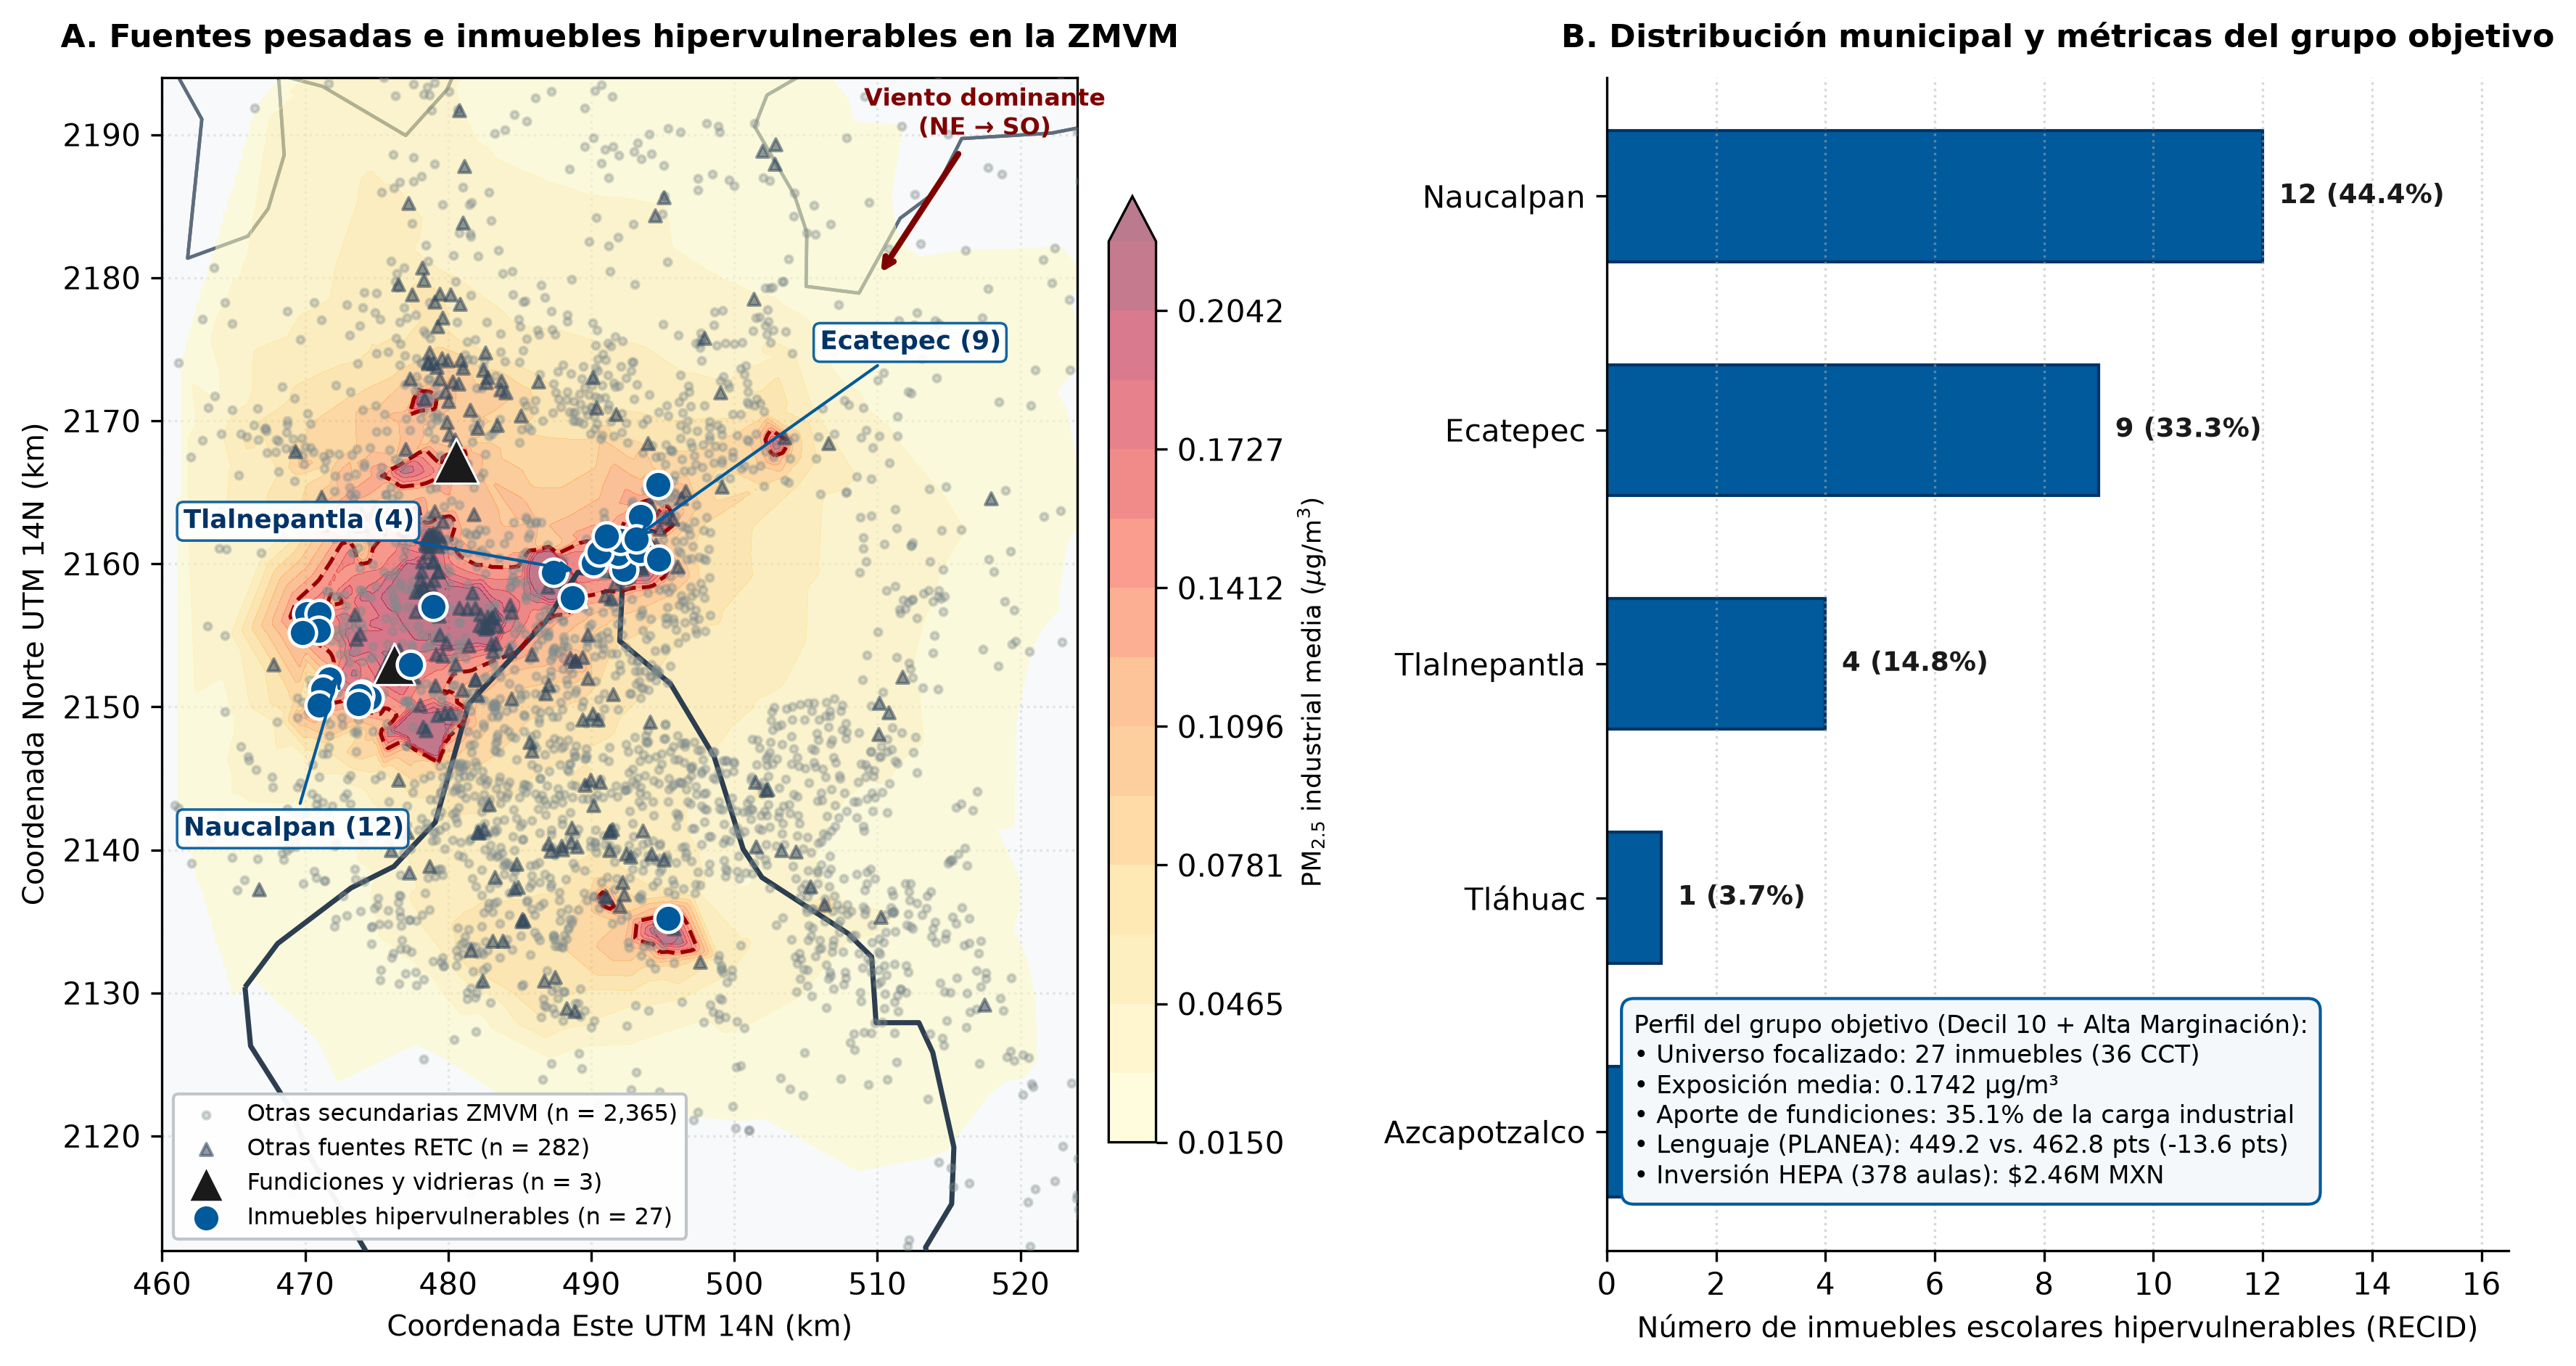


--- FILAS EXACTAS PARA APÉNDICE C (27 INMUEBLES ÚNICOS) ---
1 & \texttt{R02154} & \texttt{15DES0019Q} & Tlalnepantla de Baz & 0.3757 & 434.2 \\
2 & \texttt{R02911} & \texttt{15DTV0017Y} & Ecatepec de Morelos & 0.2187 & 449.1 \\
3 & \texttt{R00038} & \texttt{09DES0227M / 09DES4227N} & Azcapotzalco & 0.2161 & 435.5 \\
4 & \texttt{R02201} & \texttt{15DES0044P} & Ecatepec de Morelos & 0.1993 & 457.8 \\
5 & \texttt{R00472} & \texttt{09DST0108R} & Tláhuac & 0.1980 & 416.2 \\
6 & \texttt{R02140} & \texttt{15DTV0049Q} & Tlalnepantla de Baz & 0.1896 & 447.4 \\
7 & \texttt{R03141} & \texttt{15DST0063W} & Ecatepec de Morelos & 0.1880 & 469.4 \\
8 & \texttt{R01685} & \texttt{15DTV0054B} & Naucalpan de Juárez & 0.1804 & 410.4 \\
9 & \texttt{R01617} & \texttt{15DES0068Z} & Naucalpan de Juárez & 0.1776 & 431.6 \\
10 & \texttt{R02035} & \texttt{15EES0089K / 15EES0885G} & Naucalpan de Juárez & 0.1772 & 445.2 \\
11 & \texttt{R01857} & \texttt{15DTV0006S} & Tlalnepantla de Baz & 0.1753 & 424.0 \\
12 & \

In [ ]:
# === CELDA UNIFICADA: CONCILIACIÓN EXACTA + MAPA GEOPOLÍTICO (FIG 4.1) + TABLA APÉNDICE C ===
import os
import urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from scipy.interpolate import griddata

os.makedirs(f"{BASE}/figuras_tesis", exist_ok=True)

# 1. UNIFICACIÓN ESTRICTA A NIVEL DE INMUEBLE ÚNICO (RECID) -> 1 FILA = 1 EDIFICIO FÍSICO
df_rec_unico = (
    df_reg.sort_values("anio")
    .groupby("RECID", as_index=False)
    .agg(
        X_UTM=("X_UTM", "first"),
        Y_UTM=("Y_UTM", "first"),
        municipio=("municipio", "last"),
        ccts=("cct", lambda s: " / ".join(sorted(s.dropna().unique()))),
        n_ccts=("cct", "nunique"),
        es_publica=("tipo_escuela", lambda s: not s.astype(str).str.upper().str.contains("PRIVAD|PARTICULAR").any()),
        alta_marg=("alta_marg", "max"),
        PM25_mean=("PM25_ALL", "mean"),
        PM25_fund=("PM25_FUNDICION_METAL", "mean"),
        lyc_mean=("lyc_std_500", "mean"),
    )
)

# Umbral Decil 10 definido directamente sobre los 2,392 inmuebles únicos de la ZMVM
p90_recid = np.percentile(df_rec_unico["PM25_mean"], 90)
df_rec_unico["top_10_exp"] = df_rec_unico["PM25_mean"] >= p90_recid
df_rec_unico["hipervulnerable"] = (
    df_rec_unico["es_publica"]
    & (df_rec_unico["alta_marg"] == 1)
    & df_rec_unico["top_10_exp"]
)

df_hiper = df_rec_unico[df_rec_unico["hipervulnerable"]].sort_values("PM25_mean", ascending=False).reset_index(drop=True)
df_otras = df_rec_unico[~df_rec_unico["hipervulnerable"]].copy()

# Imprimir cifras exactas conciliadas para Capítulo 4 y Apéndice C
aporte_fund_hiper = 100.0 * df_hiper["PM25_fund"].sum() / df_hiper["PM25_mean"].sum()
lyc_resto_pub = df_rec_unico[df_rec_unico["es_publica"] & ~df_rec_unico["hipervulnerable"]]["lyc_mean"].mean()
n_multi_turno = (df_hiper["n_ccts"] > 1).sum()
n_aulas = len(df_hiper) * 14
capex_mxn = n_aulas * 6500 / 1e6
opex_mxn = n_aulas * 2200 / 1e6

print("=================================================================")
print("CIFRAS EXACTAS CONCILIADAS (CAPÍTULO 4, FIGURA 4.1 Y APÉNDICE C)")
print("=================================================================")
print(f"• Universo inmuebles ZMVM: {len(df_rec_unico):,}")
print(f"• Umbral Decil 10 (P90 sobre RECID): >= {p90_recid:.4f} μg/m³ ({df_rec_unico['top_10_exp'].sum()} inmuebles)")
print(f"• Inmuebles hipervulnerables ÚNICOS: {len(df_hiper)} inmuebles ({df_hiper['n_ccts'].sum()} CCTs; {n_multi_turno} comparten ambos turnos)")
print(f"• Concentración media hipervulnerables: {df_hiper['PM25_mean'].mean():.4f} μg/m³ (aporte fundición: {aporte_fund_hiper:.1f}%)")
print(f"• Lenguaje medio hipervulnerables vs. resto públicas: {df_hiper['lyc_mean'].mean():.1f} vs. {lyc_resto_pub:.1f} pts ({df_hiper['lyc_mean'].mean() - lyc_resto_pub:.1f} pts)")
print(f"• Presupuesto HEPA ({n_aulas} aulas): CAPEX = ${capex_mxn:.2f}M MXN | OPEX = ${opex_mxn:.2f}M MXN/año")
print("\nDistribución municipal exacta:")
print(df_hiper["municipio"].value_counts())

# 2. CARGAR CAPAS VECTORIALES EN UTM 14N (KM)
GEOJSON_STATES = f"{AERMAP_OUT}/mexico_estados.geojson"
GEOJSON_MUN = f"{AERMAP_OUT}/zmvm_municipios_inegi.geojson"

if not os.path.exists(GEOJSON_STATES):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/angelnmara/geojson/master/mexicoHigh.json", GEOJSON_STATES)

gdf_st = gpd.read_file(GEOJSON_STATES).to_crs("EPSG:32614")
gdf_st["geometry"] = gdf_st["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))
gdf_cdmx = gdf_st[gdf_st.geometry.centroid.x.between(470, 505) & gdf_st.geometry.centroid.y.between(2120, 2165)].copy()

gdf_mun = None
if os.path.exists(GEOJSON_MUN):
    gdf_mun = gpd.read_file(GEOJSON_MUN).to_crs("EPSG:32614")
    gdf_mun["geometry"] = gdf_mun["geometry"].scale(xfact=0.001, yfact=0.001, origin=(0, 0))

# 3. CARGAR FUENTES PESADAS PRIORITARIAS (FUNDICIÓN + VIDRIO)
df_src = pd.read_csv(f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv")
df_src["Q_MEAN"] = df_src[["Q_GS_2015", "Q_GS_2017", "Q_GS_2019"]].mean(axis=1)
df_src_zmvm = df_src[df_src["X_UTM"] >= 460000].copy()

mask_pesadas = pd.Series(False, index=df_src_zmvm.index)
for col in df_src_zmvm.select_dtypes(include=["object", "string"]).columns:
    if df_src_zmvm[col].astype(str).str.upper().str.contains("FUNDICION|VIDRIO").any():
        mask_pesadas = df_src_zmvm[col].astype(str).str.upper().str.contains("FUNDICION|VIDRIO")
        break
if not mask_pesadas.any():
    col_hs = [c for c in df_src_zmvm.columns if c.upper() in ["HS", "H_S", "ALTURA"]][0]
    mask_pesadas = df_src_zmvm[col_hs].isin([22.0, 45.0])

df_pesadas = df_src_zmvm[mask_pesadas].copy()
df_ligeras = df_src_zmvm[~mask_pesadas].copy()

# 4. INTERPOLACIÓN ESPACIAL DE PM2.5 (KM UTM)
x_km = df_rec_unico["X_UTM"].values / 1000.0
y_km = df_rec_unico["Y_UTM"].values / 1000.0
z_pm = df_rec_unico["PM25_mean"].values

xi = np.linspace(460, 524, 240)
yi = np.linspace(2112, 2194, 260)
XI, YI = np.meshgrid(xi, yi)
ZI = griddata((x_km, y_km), z_pm, (XI, YI), method="linear")

# 5. CONSTRUIR FIGURA 4.1 CON CONTORNOS GEOPOLÍTICOS Y SIN TRASLAPES
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10})
fig = plt.figure(figsize=(15.4, 7.0), dpi=300)
gs = fig.add_gridspec(1, 2, width_ratios=[1.38, 1.0], wspace=0.42)

# --- PANEL A: MAPA GEOPOLÍTICO + PLUMA + INMUEBLES HIPERVULNERABLES ---
ax1 = fig.add_subplot(gs[0])
ax1.set_facecolor("#f8f9fa")

# Capas base geopolíticas (Municipios ZMVM y contorno CDMX)
if gdf_mun is not None:
    gdf_mun.plot(ax=ax1, facecolor="#eef1f5", edgecolor="#95a5a6", linewidth=0.55, zorder=1)
gdf_st.boundary.plot(ax=ax1, color="#5d6d7e", linewidth=1.1, zorder=2)
if len(gdf_cdmx) > 0:
    gdf_cdmx.boundary.plot(ax=ax1, color="#2c3e50", linewidth=1.7, linestyle="-", zorder=3)

# Contorno de concentración industrial y umbral Decil 10
levels = np.linspace(0.015, 0.22, 14)
cf = ax1.contourf(XI, YI, np.clip(ZI, 0, 0.22), levels=levels, cmap="YlOrRd", alpha=0.52, extend="max", zorder=2)
ax1.contour(XI, YI, ZI, levels=[p90_recid], colors="#990000", linewidths=1.3, linestyles="--", zorder=4)

# Puntos de escuelas y fuentes
ax1.scatter(df_otras["X_UTM"]/1000.0, df_otras["Y_UTM"]/1000.0, s=6, c="#7f8c8d", alpha=0.32, label=f"Otras secundarias ZMVM (n = {len(df_otras):,})", zorder=4)
ax1.scatter(df_ligeras["X_UTM"]/1000.0, df_ligeras["Y_UTM"]/1000.0, s=16, marker="^", c="#34495e", alpha=0.55, label=f"Otras fuentes RETC (n = {len(df_ligeras)})", zorder=5)
ax1.scatter(
    df_pesadas["X_UTM"]/1000.0, df_pesadas["Y_UTM"]/1000.0,
    s=50 + 170 * (df_pesadas["Q_MEAN"] / df_pesadas["Q_MEAN"].max()),
    marker="^", c="#1a1a1a", edgecolors="white", linewidths=0.7,
    label=f"Fundiciones y vidrieras (n = {len(df_pesadas)})", zorder=6
)
ax1.scatter(
    df_hiper["X_UTM"]/1000.0, df_hiper["Y_UTM"]/1000.0,
    s=82, marker="o", c="#005a9c", edgecolors="white", linewidths=1.1,
    label=f"Inmuebles hipervulnerables (n = {len(df_hiper)})", zorder=7
)

# Etiquetas automáticas apuntando al centroide real de los inmuebles en los 4 municipios principales
posiciones_caja = {
    "NAUCALPAN": (461.5, 2141.0),
    "TLALNEPANTLA": (461.5, 2162.5),
    "ATIZAP": (461.5, 2175.5),
    "ECATEPEC": (506.0, 2175.0),
}
for clave_mun, (x_txt, y_txt) in posiciones_caja.items():
    sub_m = df_hiper[df_hiper["municipio"].str.upper().str.contains(clave_mun)]
    if len(sub_m) > 0:
        cx, cy = (sub_m["X_UTM"]/1000.0).mean(), (sub_m["Y_UTM"]/1000.0).mean()
        etq = f"{sub_m['municipio'].iloc[0].split()[0].title()} ({len(sub_m)})".replace("Atizapan", "Atizapán")
        ax1.annotate(
            etq, xy=(cx, cy), xytext=(x_txt, y_txt),
            fontsize=8.5, fontweight="bold", color="#003366",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#005a9c", alpha=0.92, lw=0.85),
            arrowprops=dict(arrowstyle="->", color="#005a9c", lw=1.0),
            path_effects=[pe.withStroke(linewidth=2, foreground="white")],
            zorder=8
        )

ax1.annotate(
    "Viento dominante\n(NE → SO)", xy=(510, 2180), xytext=(517.5, 2190),
    ha="center", fontsize=8, fontweight="bold", color="#7f0000",
    arrowprops=dict(arrowstyle="->", lw=2.0, color="#7f0000"), zorder=8
)

cbar = plt.colorbar(cf, ax=ax1, fraction=0.038, pad=0.025)
cbar.set_label(r"$\text{PM}_{2.5}$ industrial media ($\mu\text{g/m}^3$)", fontsize=8.5)

ax1.set_xlim(460, 524)
ax1.set_ylim(2112, 2194)
ax1.set_aspect("equal", adjustable="box")
ax1.set_xlabel("Coordenada Este UTM 14N (km)", fontsize=9.5)
ax1.set_ylabel("Coordenada Norte UTM 14N (km)", fontsize=9.5)
ax1.set_title("A. Fuentes pesadas e inmuebles hipervulnerables en la ZMVM", fontsize=10.5, fontweight="bold", pad=10)
ax1.grid(True, linestyle=":", alpha=0.4, color="#bdc3c7")
ax1.legend(loc="lower left", fontsize=7.6, framealpha=0.95, edgecolor="#bdc3c7")

# --- PANEL B: CONCENTRACIÓN MUNICIPAL Y BRECHA EDUCATIVA ---
ax2 = fig.add_subplot(gs[1])
conteo_mun = df_hiper["municipio"].value_counts().sort_values(ascending=True)
etiquetas_limpias = [
    m.title()
     .replace("De Juarez", "")
     .replace("De Morelos", "")
     .replace("De Baz", "")
     .replace("De Zaragoza", "")
     .replace("Tlahuac", "Tláhuac")
     .replace("Atizapan", "Atizapán")
     .strip()
    for m in conteo_mun.index
]

bars = ax2.barh(etiquetas_limpias, conteo_mun.values, color="#005a9c", edgecolor="#003366", height=0.56)
for bar, val in zip(bars, conteo_mun.values):
    pct = 100.0 * val / len(df_hiper)
    ax2.text(val + 0.3, bar.get_y() + bar.get_height()/2, f"{val} ({pct:.1f}%)", va="center", fontsize=8.8, fontweight="bold", color="#1a1a1a")

ax2.set_xlim(0, conteo_mun.max() + 4.5)
ax2.set_xlabel("Número de inmuebles escolares hipervulnerables (RECID)", fontsize=9.5)
ax2.set_title("B. Distribución municipal y métricas del grupo objetivo", fontsize=10.5, fontweight="bold", pad=10)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(axis="x", linestyle=":", alpha=0.5)

texto_caja = (
    "Perfil del grupo objetivo (Decil 10 + Alta Marginación):\n"
    f"• Universo focalizado: {len(df_hiper)} inmuebles ({df_hiper['n_ccts'].sum()} CCT)\n"
    f"• Exposición media: {df_hiper['PM25_mean'].mean():.4f} μg/m³\n"
    f"• Aporte de fundiciones: {aporte_fund_hiper:.1f}% de la carga industrial\n"
    f"• Lenguaje (PLANEA): {df_hiper['lyc_mean'].mean():.1f} vs. {lyc_resto_pub:.1f} pts ({df_hiper['lyc_mean'].mean() - lyc_resto_pub:.1f} pts)\n"
    f"• Inversión HEPA ({n_aulas} aulas): ${capex_mxn:.2f}M MXN"
)
ax2.text(
    0.03, 0.05, texto_caja, transform=ax2.transAxes,
    fontsize=8.2, verticalalignment="bottom",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#f4f8fb", edgecolor="#005a9c", lw=1.0)
)

out_fig = f"{BASE}/figuras_tesis/fig_politica_hipervulnerables_cap4.png"
plt.savefig(out_fig, bbox_inches="tight", dpi=300)
plt.show()

print(f"\n--- FILAS EXACTAS PARA APÉNDICE C ({len(df_hiper)} INMUEBLES ÚNICOS) ---")
for idx, r in df_hiper.iterrows():
    mun_clean = (
        r["municipio"].title()
        .replace("De ", "de ")
        .replace("Juarez", "Juárez")
        .replace("Tlahuac", "Tláhuac")
        .replace("Atizapan", "Atizapán")
    )
    print(f"{idx+1} & \\texttt{{{r['RECID']}}} & \\texttt{{{r['ccts']}}} & {mun_clean} & {r['PM25_mean']:.4f} & {r['lyc_mean']:.1f} \\\\")


In [ ]:
# =====================================================================
# CELDAS ADICIONALES PARA regresiones_twfe_cap3
# Pegar cada bloque "# %%" en una celda nueva, DESPUÉS de la Celda 10.
# Requieren que ya existan: df_reg (con id_cct_clean), controles_W,
# BASE, AERMET_OUT, pf, np, pd.
# =====================================================================

# %% === CELDA 11: ÍNDICES DE VENTANA (30D, 15D Y PLACEBO POSTERIOR AL EXAMEN) ===
# Misma fórmula de la Celda 10, reorganizada en una función para poder
# calcular también la ventana placebo (30 días DESPUÉS del examen).
import datetime
import numpy as np
import pandas as pd
import pyfixest as pf

fechas_planea = {
    2015: datetime.date(2015, 6, 17),
    2017: datetime.date(2017, 6, 14),
    2019: datetime.date(2019, 6, 11),
}

df_src = pd.read_csv(f"{BASE}/02-data/processed/aermap_out/catalogo_285_fuentes_aermod_ap42.csv")
Xs, Ys, Q_2015 = df_src["X_UTM"].values, df_src["Y_UTM"].values, df_src["Q_GS_2015"].values

rec_unicos = df_reg[["RECID", "X_UTM", "Y_UTM"]].drop_duplicates().reset_index(drop=True)
dx_km = (rec_unicos["X_UTM"].values[:, None] - Xs[None, :]) / 1000.0
dy_km = (rec_unicos["Y_UTM"].values[:, None] - Ys[None, :]) / 1000.0
dist_km = np.maximum(np.sqrt(dx_km**2 + dy_km**2), 0.25)
ux, uy = dx_km / dist_km, dy_km / dist_km
aten_dist = 1.0 / (dist_km ** 1.5)

f_emisfact_24 = np.array([
    0.65, 0.62, 0.60, 0.60, 0.63, 0.72,
    0.88, 1.05, 1.18, 1.25, 1.28, 1.30,
    1.28, 1.25, 1.26, 1.28, 1.26, 1.22,
    1.15, 1.05, 0.92, 0.82, 0.75, 0.68
])

# Ventanas en "días antes del examen" (negativo = después del examen)
#   30D:    0 a 30 días antes (igual que la Celda 10)
#   15D:    0 a 15 días antes (igual que la Celda 10)
#   POST30: 1 a 30 días DESPUÉS del examen (placebo)
VENTANAS = {"30D": (0, 30), "15D": (0, 15), "POST30": (-30, -1)}
TURNOS = {"MAT": (7, 13), "VESP": (13, 19)}


def leer_horas_sfc(yr):
    """Lee el .sfc de AERMET y devuelve las horas válidas con fecha, viento y capa de mezcla."""
    f_exam = fechas_planea[yr]
    filas = []
    with open(f"{AERMET_OUT}/aer_{yr}.sfc", "r") as f:
        for line in f.readlines()[1:]:
            p = line.split()
            if len(p) < 22:
                continue
            mo, dy, hr = int(p[1]), int(p[2]), int(p[4])
            zic, zim = float(p[9]), float(p[10])
            ws, wd = float(p[15]), float(p[16])
            if not (0 < ws < 50 and 0 <= wd <= 360):
                continue
            try:
                fecha = datetime.date(yr, mo, dy)
            except ValueError:
                continue
            z_mix = max([v for v in [zic, zim, 150.0] if 0 < v < 5000])
            trap = f_emisfact_24[(hr - 1) % 24] / (max(ws, 0.5) * np.sqrt(z_mix / 500.0))
            filas.append(((f_exam - fecha).days, fecha.weekday(), hr, wd, trap))
    return pd.DataFrame(filas, columns=["dias_antes", "dow", "hr", "wd", "trap"])


def indice_cono(sub, Q):
    """Índice de alineación del viento (cono^10) ponderado por atrapamiento, para un vector de emisiones Q."""
    out = np.zeros(len(rec_unicos))
    if len(sub) == 0:
        return out
    wd_rad = np.deg2rad(sub["wd"].values)
    wx_u, wy_u = -np.sin(wd_rad), -np.cos(wd_rad)
    sectores = np.floor(sub["wd"].values / 10.0).astype(int) % 36
    trap = sub["trap"].values
    for sec in range(36):
        m = (sectores == sec)
        if not np.any(m):
            continue
        wx_m, wy_m = np.mean(wx_u[m]), np.mean(wy_u[m])
        norm = max(np.sqrt(wx_m**2 + wy_m**2), 1e-6)
        cono = np.maximum(0.0, ux * (wx_m / norm) + uy * (wy_m / norm)) ** 10
        out += np.sum(cono * (aten_dist * Q[None, :]), axis=1) * (np.sum(trap[m]) / len(sub))
    return out


registros = []
for yr in fechas_planea:
    Q_yr = df_src[f"Q_GS_{yr}"].values
    df_h = leer_horas_sfc(yr)
    df_h = df_h[(df_h["dow"] < 5) & (df_h["hr"].between(7, 19))]
    res = rec_unicos[["RECID"]].copy()
    res["anio"] = yr
    for w_nom, (d_ini, d_fin) in VENTANAS.items():
        for t_nom, (h1, h2) in TURNOS.items():
            sub = df_h[df_h["dias_antes"].between(d_ini, d_fin) & df_h["hr"].between(h1, h2)]
            res[f"IVRAW_{w_nom}_{t_nom}"] = indice_cono(sub, Q_2015)   # emisiones fijas de 2015
            res[f"EXP_{w_nom}_{t_nom}"] = indice_cono(sub, Q_yr)       # emisiones del año
    registros.append(res)
df_v = pd.concat(registros, ignore_index=True)

# Misma escala que la Celda 10 (referida a EXP_30D_MAT) para todas las ventanas
escala = df_reg["PM25_ALL"].mean() / df_v["EXP_30D_MAT"].mean()
for c in [c for c in df_v.columns if c.startswith("IVRAW_")]:
    df_v[c.replace("IVRAW_", "IV_")] = (df_v[c] - df_v[c].mean()) / df_v[c].std()
for c in [c for c in df_v.columns if c.startswith("EXP_")]:
    df_v[c.replace("EXP_", "PM25_")] = df_v[c] * escala

cols_v = [c for c in df_v.columns if c.startswith(("IV_", "PM25_"))]
cols_turno = [f"{p}_{w}{s}" for p in ["PM25", "IV"] for w in VENTANAS for s in ["", "_x_Marg"]]
df_reg = df_reg.drop(columns=[c for c in cols_v + cols_turno if c in df_reg.columns]).merge(
    df_v[["RECID", "anio"] + cols_v], on=["RECID", "anio"], how="left"
)

# Asignación por turno (misma regla de la Celda 10)
es_vesp = df_reg["turno"].astype(str).str.upper().str.contains("VESP|2").values
for w_nom in VENTANAS:
    df_reg[f"PM25_{w_nom}"] = np.where(es_vesp, df_reg[f"PM25_{w_nom}_VESP"], df_reg[f"PM25_{w_nom}_MAT"])
    df_reg[f"IV_{w_nom}"] = np.where(es_vesp, df_reg[f"IV_{w_nom}_VESP"], df_reg[f"IV_{w_nom}_MAT"])
    df_reg[f"PM25_{w_nom}_x_Marg"] = df_reg[f"PM25_{w_nom}"] * df_reg["alta_marg"]

df_pub = df_reg[~df_reg["tipo_escuela"].astype(str).str.upper().str.contains("PRIVAD|PARTICULAR", na=False)].copy()
print(f"[OK] Ventanas construidas: {list(VENTANAS)} | Observaciones: todas = {len(df_reg):,}, públicas = {len(df_pub):,}")



[OK] Ventanas construidas: ['30D', '15D', 'POST30'] | Observaciones: todas = 9,459, públicas = 7,161


In [ ]:

# %% === CELDA 12: TABLA COMPLETA DE VENTANAS (LENGUAJE Y MATEMÁTICAS) ===
# Para cada ventana y asignatura, en secundarias públicas:
#   (a) TWFE promedio (SIN interacción)  <- el comparable con el 2SLS
#   (b) TWFE con interacción de marginación
#   (c) Forma reducida (resultado ~ instrumento)
#   (d) 2SLS
#   (e) 2SLS con errores agrupados por municipio
#   (f) 2SLS con efectos fijos de municipio por año
FE = "id_cct_clean + anio"
VC = {"CRV1": "RECID"}
DEPVARS = {"Lenguaje": "lyc_std_500", "Matemáticas": "mat_std_500"}


def fila(ventana, asignatura, modelo, fit, var, extra=""):
    return {
        "ventana": ventana, "asignatura": asignatura, "modelo": modelo, "variable": var,
        "coef": round(float(fit.coef()[var]), 3), "se": round(float(fit.se()[var]), 3),
        "p": round(float(fit.pvalue()[var]), 4), "N": getattr(fit, "_N", np.nan), "nota": extra,
    }


def estimar_ventana(w, datos, etiqueta_muestra="Públicas"):
    filas = []
    x, z, xm = f"PM25_{w}", f"IV_{w}", f"PM25_{w}_x_Marg"
    fs = pf.feols(f"{x} ~ {z} + {controles_W} | {FE}", data=datos, vcov=VC, collin_tol=1e-12)
    F1 = float(fs.tstat()[z]) ** 2
    for asig, y in DEPVARS.items():
        m_a = pf.feols(f"{y} ~ {x} + {controles_W} | {FE}", data=datos, vcov=VC)
        m_b = pf.feols(f"{y} ~ {x} + {xm} + {controles_W} | {FE}", data=datos, vcov=VC)
        m_c = pf.feols(f"{y} ~ {z} + {controles_W} | {FE}", data=datos, vcov=VC)
        m_d = pf.feols(f"{y} ~ {controles_W} + [{x} ~ {z}] | {FE}", data=datos, vcov=VC, collin_tol=1e-12)
        m_e = pf.feols(f"{y} ~ {controles_W} + [{x} ~ {z}] | {FE}", data=datos, vcov={"CRV1": "municipio"}, collin_tol=1e-12)
        m_f = pf.feols(f"{y} ~ {controles_W} + [{x} ~ {z}] | id_cct_clean + mun_anio", data=datos, vcov=VC, collin_tol=1e-12)
        filas += [
            fila(w, asig, "(a) TWFE promedio", m_a, x),
            fila(w, asig, "(b) TWFE interacción: efecto base", m_b, x),
            fila(w, asig, "(b) TWFE interacción: x Alta Marg.", m_b, xm),
            fila(w, asig, "(c) Forma reducida", m_c, z, "coef. por 1 DE del instrumento"),
            fila(w, asig, "(d) 2SLS", m_d, x, f"F 1a etapa = {F1:.2f}"),
            fila(w, asig, "(e) 2SLS, cluster municipio", m_e, x),
            fila(w, asig, "(f) 2SLS, EF municipio x año", m_f, x),
        ]
    out = pd.DataFrame(filas)
    out.insert(0, "muestra", etiqueta_muestra)
    return out


import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tabla_ventanas = pd.concat(
        [estimar_ventana(w, df_pub) for w in ["30D", "15D"]], ignore_index=True
    )

pd.set_option("display.max_rows", 200, "display.width", 220)
print("=== VENTANAS PREVIAS AL EXAMEN, SECUNDARIAS PÚBLICAS ===")
print(tabla_ventanas.to_string(index=False))

# Razón 2SLS / TWFE promedio (comparación entre parámetros equivalentes)
for w in ["30D", "15D"]:
    for asig in DEPVARS:
        t = tabla_ventanas[(tabla_ventanas.ventana == w) & (tabla_ventanas.asignatura == asig)]
        b_twfe = t[t.modelo == "(a) TWFE promedio"]["coef"].iloc[0]
        b_iv = t[t.modelo == "(d) 2SLS"]["coef"].iloc[0]
        razon = b_iv / b_twfe if b_twfe != 0 else np.nan
        print(f"Ventana {w}, {asig}: TWFE promedio = {b_twfe:.3f} | 2SLS = {b_iv:.3f} | razón = {razon:.2f}")


=== VENTANAS PREVIAS AL EXAMEN, SECUNDARIAS PÚBLICAS ===
 muestra ventana  asignatura                             modelo        variable    coef     se      p    N                           nota
Públicas     30D    Lenguaje                  (a) TWFE promedio        PM25_30D -16.530 10.964 0.1318 5922                               
Públicas     30D    Lenguaje  (b) TWFE interacción: efecto base        PM25_30D -12.168 11.954 0.3089 5922                               
Públicas     30D    Lenguaje (b) TWFE interacción: x Alta Marg. PM25_30D_x_Marg -42.010 25.813 0.1038 5922                               
Públicas     30D    Lenguaje                 (c) Forma reducida          IV_30D  -7.242  3.218 0.0246 5922 coef. por 1 DE del instrumento
Públicas     30D    Lenguaje                           (d) 2SLS        PM25_30D -31.014 13.881 0.0256 5922            F 1a etapa = 121.24
Públicas     30D    Lenguaje        (e) 2SLS, cluster municipio        PM25_30D -31.014 10.720 0.0047 5922         

In [ ]:


# %% === CELDA 13: PLACEBO CON EL VIENTO POSTERIOR AL EXAMEN ===
# Si el instrumento capta exposición previa al examen, el viento de los 30 días
# POSTERIORES no debería estar asociado con el puntaje.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tabla_placebo = estimar_ventana("POST30", df_pub)

print("=== PLACEBO: 1 A 30 DÍAS DESPUÉS DEL EXAMEN, SECUNDARIAS PÚBLICAS ===")
print(tabla_placebo[tabla_placebo.modelo.isin(["(c) Forma reducida", "(d) 2SLS", "(e) 2SLS, cluster municipio"])].to_string(index=False))

# Prueba conjunta: ventana previa y posterior en la misma forma reducida
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for asig, y in DEPVARS.items():
        m = pf.feols(f"{y} ~ IV_30D + IV_POST30 + {controles_W} | {FE}", data=df_pub, vcov=VC)
        print(f"\n{asig}: forma reducida conjunta")
        print(f"  IV_30D (previo):     coef = {m.coef()['IV_30D']:.3f}, SE = {m.se()['IV_30D']:.3f}, p = {m.pvalue()['IV_30D']:.4f}")
        print(f"  IV_POST30 (placebo): coef = {m.coef()['IV_POST30']:.3f}, SE = {m.se()['IV_POST30']:.3f}, p = {m.pvalue()['IV_POST30']:.4f}")
print("\nCorrelación entre instrumentos previo y posterior:",
      round(df_pub[["IV_30D", "IV_POST30"]].corr().iloc[0, 1], 3))



=== PLACEBO: 1 A 30 DÍAS DESPUÉS DEL EXAMEN, SECUNDARIAS PÚBLICAS ===
 muestra ventana  asignatura                      modelo    variable    coef     se      p    N                           nota
Públicas  POST30    Lenguaje          (c) Forma reducida   IV_POST30  -6.299  3.578 0.0785 5922 coef. por 1 DE del instrumento
Públicas  POST30    Lenguaje                    (d) 2SLS PM25_POST30 -26.786 14.250 0.0603 5922            F 1a etapa = 107.26
Públicas  POST30    Lenguaje (e) 2SLS, cluster municipio PM25_POST30 -26.786 12.107 0.0294 5922                               
Públicas  POST30 Matemáticas          (c) Forma reducida   IV_POST30  -2.496  2.798 0.3726 5922 coef. por 1 DE del instrumento
Públicas  POST30 Matemáticas                    (d) 2SLS PM25_POST30 -10.613 11.987 0.3761 5922            F 1a etapa = 107.26
Públicas  POST30 Matemáticas (e) 2SLS, cluster municipio PM25_POST30 -10.613 17.912 0.5549 5922                               

Lenguaje: forma reducida conjunta
  IV_3

In [ ]:

# %% === CELDA 14: ¿EL ÍNDICE ANALÍTICO SE PARECE A LA EXPOSICIÓN DE AERMOD? ===
# Correlación entre el índice de 30 días y PM25_ALL (AERMOD anual), total y
# dentro de cada unidad (quitando medias por escuela-turno y por año).
def within(s, datos):
    return s - s.groupby(datos["id_cct_clean"]).transform("mean") - s.groupby(datos["anio"]).transform("mean") + s.mean()

d = df_reg.dropna(subset=["PM25_ALL", "PM25_30D", "PM25_15D"]).copy()
for v in ["PM25_30D", "PM25_15D"]:
    r_tot = d["PM25_ALL"].corr(d[v])
    r_w = within(d["PM25_ALL"], d).corr(within(d[v], d))
    print(f"{v} vs PM25_ALL (AERMOD): correlación total = {r_tot:.3f} | correlación dentro de unidad = {r_w:.3f}")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fs_aermod = pf.feols(f"PM25_ALL ~ IV_30D + {controles_W} | {FE}", data=df_reg, vcov=VC, collin_tol=1e-12)
print(f"Primera etapa con AERMOD como variable instrumentada (PM25_ALL ~ IV_30D): "
      f"t = {fs_aermod.tstat()['IV_30D']:.2f}, F = {fs_aermod.tstat()['IV_30D']**2:.2f}")



PM25_30D vs PM25_ALL (AERMOD): correlación total = 0.358 | correlación dentro de unidad = 0.283
PM25_15D vs PM25_ALL (AERMOD): correlación total = 0.351 | correlación dentro de unidad = 0.282
Primera etapa con AERMOD como variable instrumentada (PM25_ALL ~ IV_30D): t = 2.80, F = 7.83


In [ ]:

# %% === CELDA 15: DIAGNÓSTICO DE TURNOS Y UNIDADES OBSERVADAS UNA SOLA VEZ ===
t_clean = df_reg["id_cct_clean"].str.split("_").str[-1]
print("=== Etiquetas de turno por año (después de normalizar) ===")
print(pd.crosstab(t_clean, df_reg["anio"]))

print("\n=== Etiquetas de turno ORIGINALES por año ===")
print(pd.crosstab(df_reg["turno"].astype(str).str.strip(), df_reg["anio"]))

n_por_unidad = df_reg.groupby("id_cct_clean")["anio"].nunique()
n_por_cct = df_reg.groupby("cct")["anio"].nunique()
print("\n=== Número de años observados ===")
print("Por escuela-turno (id_cct_clean):", n_por_unidad.value_counts().sort_index().to_dict())
print("Por CCT:                         ", n_por_cct.value_counts().sort_index().to_dict())

# CCT que se observan en varios años pero cuyas unidades escuela-turno quedan solas
cct_multi = set(n_por_cct[n_por_cct > 1].index)
solas = n_por_unidad[n_por_unidad == 1].index
cct_de_solas = df_reg[df_reg["id_cct_clean"].isin(solas)]["cct"]
n_recuperables = cct_de_solas.isin(cct_multi).sum()
print(f"\nObservaciones en unidades de un solo año: {len(cct_de_solas):,}")
print(f"  de ellas, su CCT sí aparece en varios años: {n_recuperables:,} "
      f"(posible cambio de etiqueta de turno entre levantamientos)")

# Turnos distintos de matutino/vespertino, que la Celda 10 trata como matutino
otros = df_reg[~df_reg["turno"].astype(str).str.upper().str.contains("MAT|VESP|1|2")]
print(f"\nObservaciones con turno distinto de matutino o vespertino: {len(otros):,} "
      f"({100 * len(otros) / len(df_reg):.1f}% de la muestra)")

=== Etiquetas de turno por año (después de normalizar) ===
anio             2015  2017  2019
id_cct_clean                     
AMPLIADO          121     0     0
COMPLETO           49     0     0
DISCONTINUO         5   978     6
JORNADA AMPLIAD     0     0   145
MATUTINO         2211  1528  2189
NOCTURNO           39    38    39
TIEMPO COMPLETO     0   174    49
VESPERTINO        736   433   719

=== Etiquetas de turno ORIGINALES por año ===
anio              2015  2017  2019
turno                             
AMPLIADO           121     0     0
COMPLETO            49     0     0
DISCONTINUO          5   978     6
JORNADA AMPLIAD      0     0   145
JORNADA AMPLIADA     0   124     0
MATUTINO          2211  1528  2189
NOCTURNO            39    38    39
TIEMPO COMPLETO      0    50    49
VESPERTINO         736   433   719

=== Número de años observados ===
Por escuela-turno (id_cct_clean): {1: 1432, 2: 1048, 3: 1977}
Por CCT:                          {3: 2964}

Observaciones en unidades d